# Store demand forecast: from daily sales forecasts to a weekly stock order

This project is a prototype and is not financial advice.

## The story
Imagine the owner of one small shop who orders stock every Monday morning for the week, Monday to Sunday. Too little stock loses sales, too much wastes money. The owner needs one number per item: how many units should I order?

I forecast the daily sales of 8 items, add up the 7 days, add a small safety margin (a "buffer") and turn that into the weekly order. Then I measure how close the forecasts are and what the orders would have cost.

The shop owner is hypothetical. The data is a public Kaggle file that looks synthetic (made up by a program), so results may not carry over to a real shop.

**The question:** does a forecasting model make better weekly orders than very simple rules such as "order what we sold the same week last year"? Where does it still go wrong?

The code is in the folder `src/`. This notebook imports it and explains the key steps.

## Results at a glance (the test, read from the saved result files)

*(From the saved result files in `results/`. The explanations are in sections 9 to 11.)*

Test period 2017-10-01 to 2017-12-31, 8 items, 13 full order weeks. Lower is better everywhere. Order cost uses 3 : 1 (an assumption), once with the buffer chosen on validation and once with no buffer.

| Method | Daily MAE | SMAPE % | Weekly MAE | Order cost, tuned buffer | Order cost, buffer 0 |
|---|---|---|---|---|---|
| same day last week (lag 7) | 8.68 | 19.81 | 24.76 | 4050 | 4341 |
| mean of the last 4 same weekdays (mean4) | 8.14 | 18.17 | 34.33 | 4929 | 5043 |
| same day last year (lag 364) | 8.14 | 19.12 | 26.45 | 4188 | 7257 |
| Ridge | 6.38 | 16.16 | 21.85 | 3972 | 5036 |
| boosting | 6.18 | 14.36 | 18.09 | 3100 | 4403 |

- **Main model (gradient boosting) against the baselines fixed in advance:** daily MAE 6.18 against 8.14 (mean4); weekly MAE 18.09 against 26.45 (lag 364).
- **Order cost at 3 : 1 with tuned buffers:** 3100 against 4188 for the baseline fixed in advance (lag 364), -26.0%, 95% interval -1565 to -574. At 1 : 1: -25.3% (interval -878 to -339); at 5 : 1: -25.9% (interval -1982 to -525).
- **Where it is not a clear win:** with no buffer, a simple rule ("same day last week") is the cheapest method at 3 : 1 and 5 : 1. Ridge does not clearly beat the simple rules on cost. On one item (item 25) a simple rule beat boosting at every ratio.
- **Main failure finding:** much of the remaining error looks like random noise. The worst days are surprises that the simple rules missed too (9 of the 10 worst days), and boosting's forecasts lean low.

The sections below explain every step and show where each number comes from.

## 1. Setup and data

**What this does.** Loads the Python tools, prints their versions (so the run can be reproduced) and checks that the notebook was opened from the project folder.

**The data.** One file, `train.csv`, from the Kaggle competition "Store Item Demand Forecasting" (included in the repo root for convenience; see `data/README.md`). It has four columns: the `date`, the `store`, the `item` and `sales` (units sold that day). It runs from 2013-01-01 to 2017-12-31.

In [1]:
import sys, os, json, inspect, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn
from IPython.display import Image, display, Markdown

%matplotlib inline

ROOT = Path.cwd()
assert (ROOT / "src").is_dir() and (ROOT / "train.csv").is_file(), \
    "Open this notebook from the project folder (the one that contains src/ and train.csv); see data/README.md"
sys.path.insert(0, str(ROOT / "src"))
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)


def check(name, ok):
    """Print PASS/FAIL; stop on FAIL."""
    print(("PASS  " if ok else "FAIL  ") + name)
    assert ok, name


print("Python", platform.python_version())
for lib in (np, pd, sklearn, matplotlib, scipy):
    print(f"{lib.__name__:12s}", lib.__version__)
print("Project folder:", ROOT.name, "(shown as the folder name only)")

Python 3.12.3
numpy        2.5.4
pandas       3.1.1
sklearn      1.9.1
matplotlib   3.11.2
scipy        1.18.1
Project folder: store-demand-forecast (shown as the folder name only)


### Loading the data and cutting it at 2017-09-30

**The rule that protects the test.** The last three months of data (2017-10-01 to 2017-12-31) are the **test period**. I pretend they have not happened yet. The project's loader `load_scope` reads the file and **drops every row after 2017-09-30 immediately**. Only the guarded final test run later in this notebook can load data past that date.

**Three time periods**, always in time order and never shuffled, because a forecast must never use the future:

| Period | Dates | Used for |
|---|---|---|
| train | up to 2017-06-30 | fitting the models |
| validation | 2017-07-01 to 2017-09-30 | comparing methods and choosing settings |
| test | 2017-10-01 to 2017-12-31 | one final score, produced at the end by the guarded run (section 8) |

For the test, the models are refitted on train + validation and then forecast the test quarter.

In [2]:
import inspect
import forecast
from data_prep import TRAIN_END, VAL_START, VAL_END, TEST_START, TEST_END
from forecast import load_scope, VAL_WEEK_MONDAYS, TEST_WEEK_MONDAYS
from features import check_daily_grid

print(inspect.getsource(load_scope))

def load_scope(until, ticket=None):
    """Load chosen store and items up to `until`.

    - later rows dropped right after reading
    - cut-off after 2017-09-30 needs the guard's ticket
    """
    if until > VAL_END:
        require_active_ticket(ticket, "load_scope with a cut-off after 2017-09-30")
        require(ticket.results_dir == RESULTS.resolve(),
                "the ticket belongs to a different results folder")
    scope = json.loads((RESULTS / "scope.json").read_text())
    df = load_data(ROOT / "train.csv")
    df = select_scope(df, scope["store"], scope["items"])
    df = df.loc[df["date"] <= until, ["date", "item", "sales"]].reset_index(drop=True)
    require(df["date"].max() <= until, "rows after the cut-off date are still present")
    return df, scope



**Load and check the data.** Loads the 8 items up to 2017-09-30 (the loader drops every later row), then checks that there are no gaps, missing values, negative sales or duplicate rows, and prints the three time periods with their full order weeks.

In [3]:
df, scope = load_scope(VAL_END)          # - drops rows after 2017-09-30
check_daily_grid(df)                      # - one row per item-day, no gaps

check("no row dated after 2017-09-30 is in memory", df["date"].max() <= VAL_END)
check("no missing values", not df.isna().any().any())
check("no negative sales", (df["sales"] >= 0).all())
check("exactly one row per item and date", not df.duplicated(["item", "date"]).any())
print(f"\nStore {scope['store']}, items {scope['items']}")
print(f"{len(df):,} rows, {df['date'].min().date()} to {df['date'].max().date()}")

periods = pd.DataFrame({
    "start": [df["date"].min(), VAL_START, TEST_START],
    "end": [TRAIN_END, VAL_END, TEST_END],
}, index=["train", "validation", "test"])
periods["start weekday"] = periods["start"].dt.day_name()
periods["end weekday"] = periods["end"].dt.day_name()
periods["full Mon-Sun order weeks"] = ["-", len(VAL_WEEK_MONDAYS), len(TEST_WEEK_MONDAYS)]
display(periods)

PASS  no row dated after 2017-09-30 is in memory
PASS  no missing values
PASS  no negative sales
PASS  exactly one row per item and date

Store 1, items [5, 15, 16, 20, 25, 31, 33, 42]
13,872 rows, 2013-01-01 to 2017-09-30


,start,end,start weekday,end weekday,full Mon-Sun order weeks
train,2013-01-01,2017-06-30,Tuesday,Friday,-
validation,2017-07-01,2017-09-30,Saturday,Saturday,12
test,2017-10-01,2017-12-31,Sunday,Sunday,13


**Why full Monday-to-Sunday weeks.** The owner orders for whole weeks, so the order simulation uses only full weeks: 12 in validation (first Monday 2017-07-03) and 13 in the test (first Monday 2017-10-02). The few days at the edges are still scored as days but are not part of a weekly order.

## 2. Exploring the data (training data only) and choosing the scope

**What this does.** I look at the training data (up to 2017-06-30) to see what a good forecast has to capture. All numbers and figures in this section come from `src/eda.py` and are saved in `results/`.

**The scope choice (made before any model was fitted).** Using every store and item would be slow to explain, so I keep **store 1** and **8 of its 50 items**. The rule, written down before looking at any results: rank the 50 items by their mean daily sales in the training period, then take 8 items evenly spaced along that ranking (the lowest, the highest and six in between). This gives a mix of small and large sellers.

In [4]:
with open(RESULTS / "scope.json") as f:
    scope_file = json.load(f)
print("Store:", scope_file["store"], "  Items:", scope_file["items"])
print("Rule:", scope_file["selection_rule"])
print("Chosen from:", scope_file["selection_period"])
check("scope.json agrees with the data in memory", sorted(scope_file["items"]) == sorted(df["item"].unique()))

items = pd.read_csv(RESULTS / "eda_item_summary.csv")
chosen = items[items["chosen"]].sort_values("volume_rank_low_to_high")
chosen = chosen.rename(columns={"mean": "mean daily sales", "std": "std", "cv": "std / mean"})
display(chosen[["item", "volume_rank_low_to_high", "mean daily sales", "std", "min", "max", "std / mean"]]
        .round(2).reset_index(drop=True))

Store: 1   Items: [5, 15, 16, 20, 25, 31, 33, 42]
Rule: Store 1. Rank the 50 items by mean daily sales in the training period (lowest to highest). Take 8 items evenly spaced along that ranking: rank positions round(linspace(0, 49, 8)) = 0, 7, 14, 21, 28, 35, 42, 49 (0 = lowest volume, 49 = highest volume).
Chosen from: 2013-01-01 to 2017-06-30 (training period only)
PASS  scope.json agrees with the data in memory


,item,volume_rank_low_to_high,mean daily sales,std,min,max,std / mean
0,5,0,16.34,5.63,3,36,0.34
1,16,7,22.90,7.43,5,50,0.32
2,42,14,32.53,9.46,7,71,0.29
3,20,21,42.12,11.94,11,86,0.28
4,31,28,51.91,14.59,15,106,0.28
5,33,35,61.47,16.77,23,118,0.27
6,25,42,71.29,19.45,24,143,0.27
7,15,49,78.06,21.29,17,147,0.27


**Reading the table.** Small items sell about 16 units a day, large ones about 78. The last column (spread divided by average) is larger for small items: small numbers are relatively noisier, so they are harder to forecast in percent terms. No chosen item ever sold zero units on a day, so I do not need special methods for items that sometimes sell nothing.

### Four pictures of the training data

**Figure 1: average daily sales per chosen item.** Shows the size differences between the items.

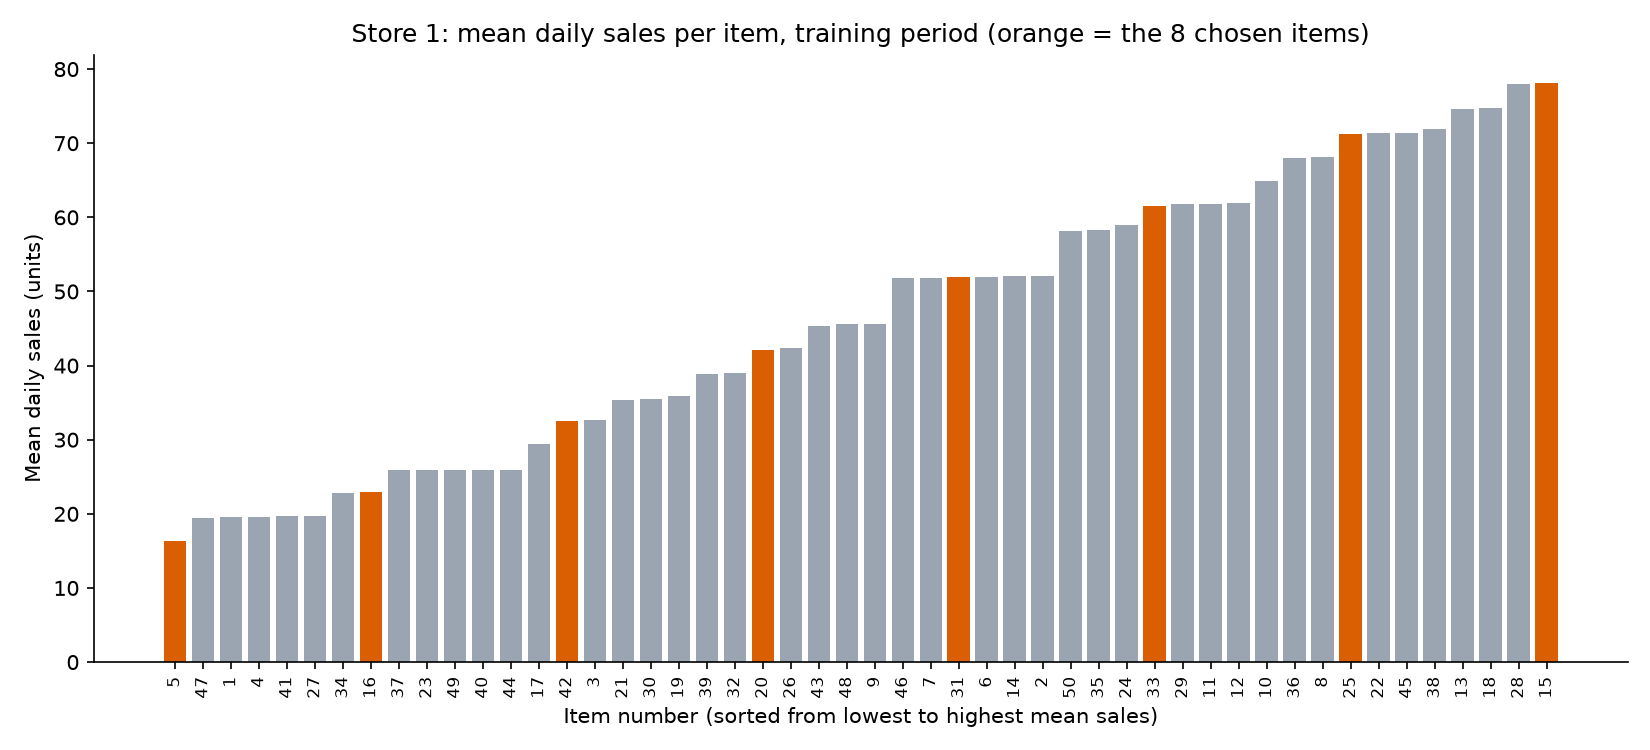

In [5]:
display(Image(filename=str(FIGURES / "eda_item_means.png"), width=700))

**Figure 2: the weekly pattern.** Each line is one item's average sales per weekday, divided by that
item's own overall average (1.0 = an average day), so items of different size sit on the same scale.
All items rise from Monday to Sunday. The shape is almost the same for every item.

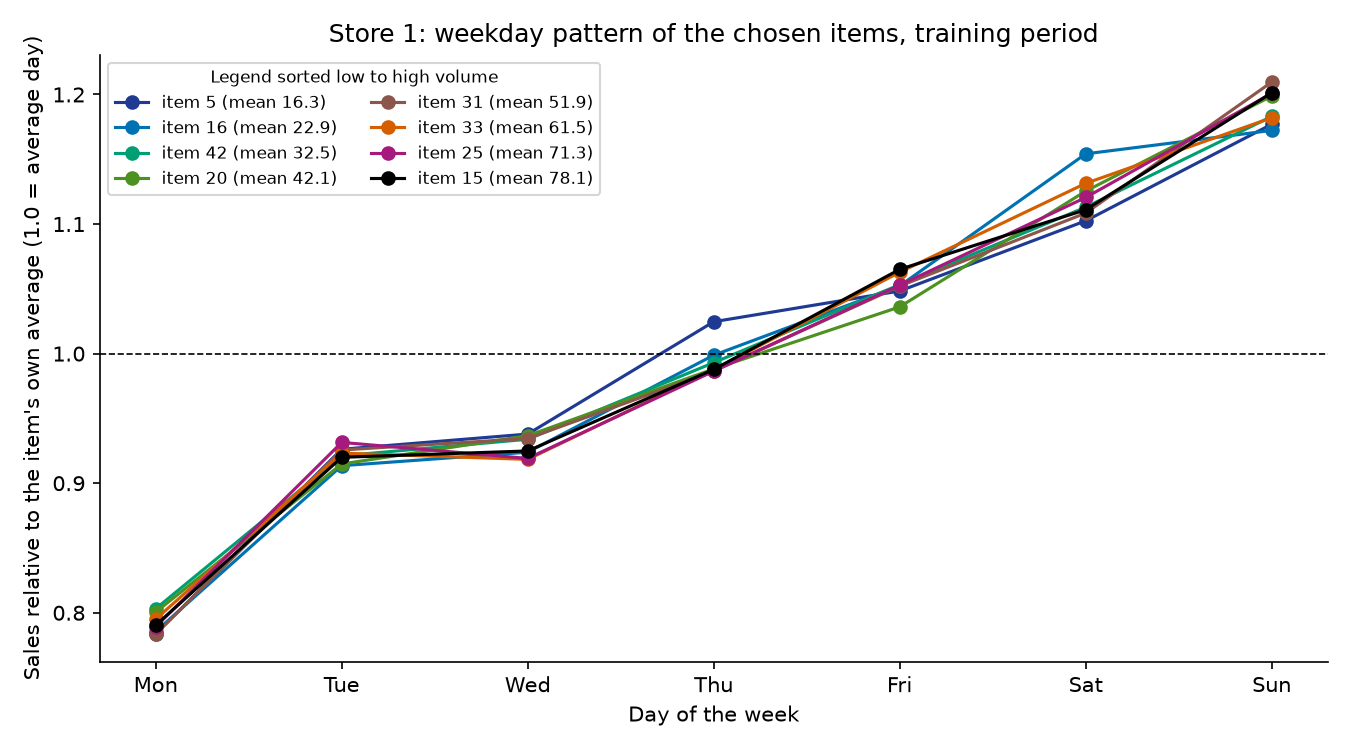

In [6]:
display(Image(filename=str(FIGURES / "eda_weekly_pattern.png"), width=700))

**Figure 3: the yearly pattern.** Same idea for months. Sales are low in winter and peak in July.
(January to June are averaged over 5 years, July to December over 4, because the 2017 data is only
used up to the end of the training period here.)

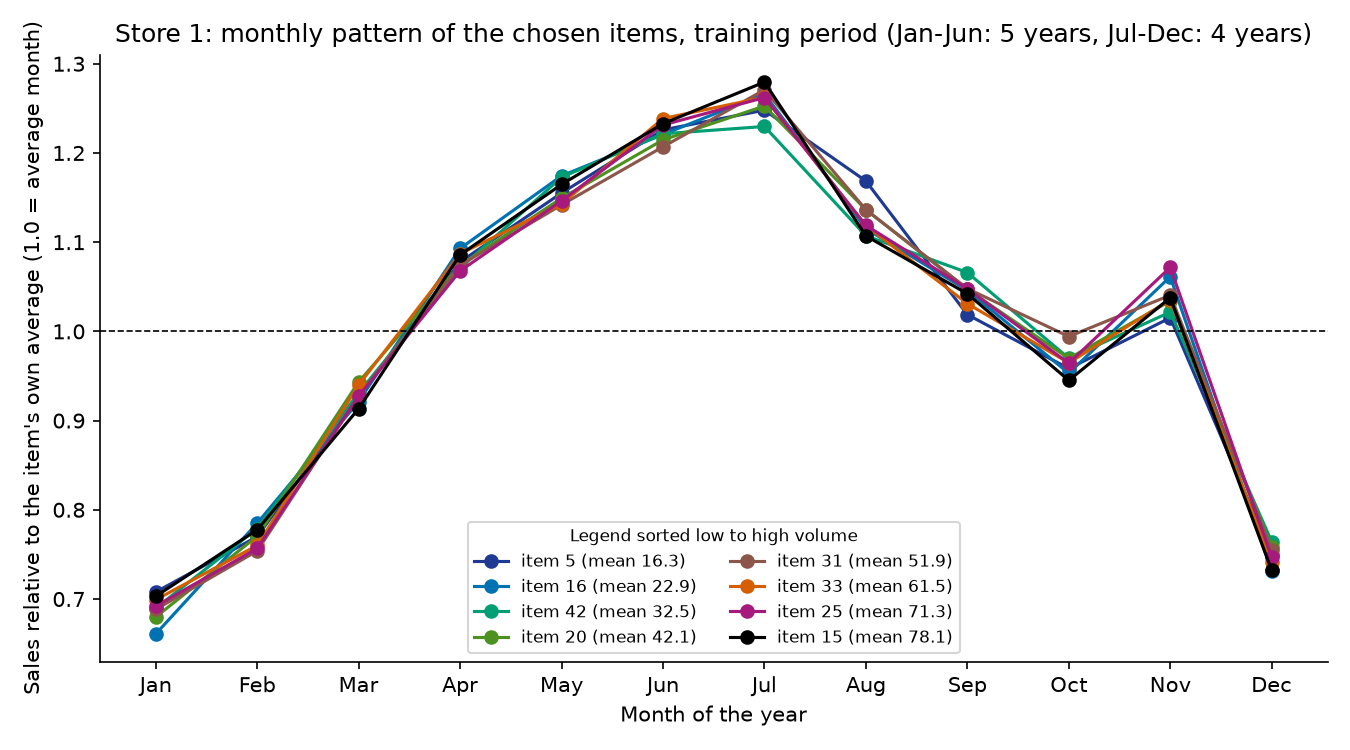

In [7]:
display(Image(filename=str(FIGURES / "eda_yearly_pattern.png"), width=700))

**Figure 4: daily series for a small, a medium and a large item.** The thin grey line is daily sales,
the blue line is a 28-day average. The yellow band is the validation period. The test period is only an
empty hatched band: nothing after 2017-09-30 is drawn.

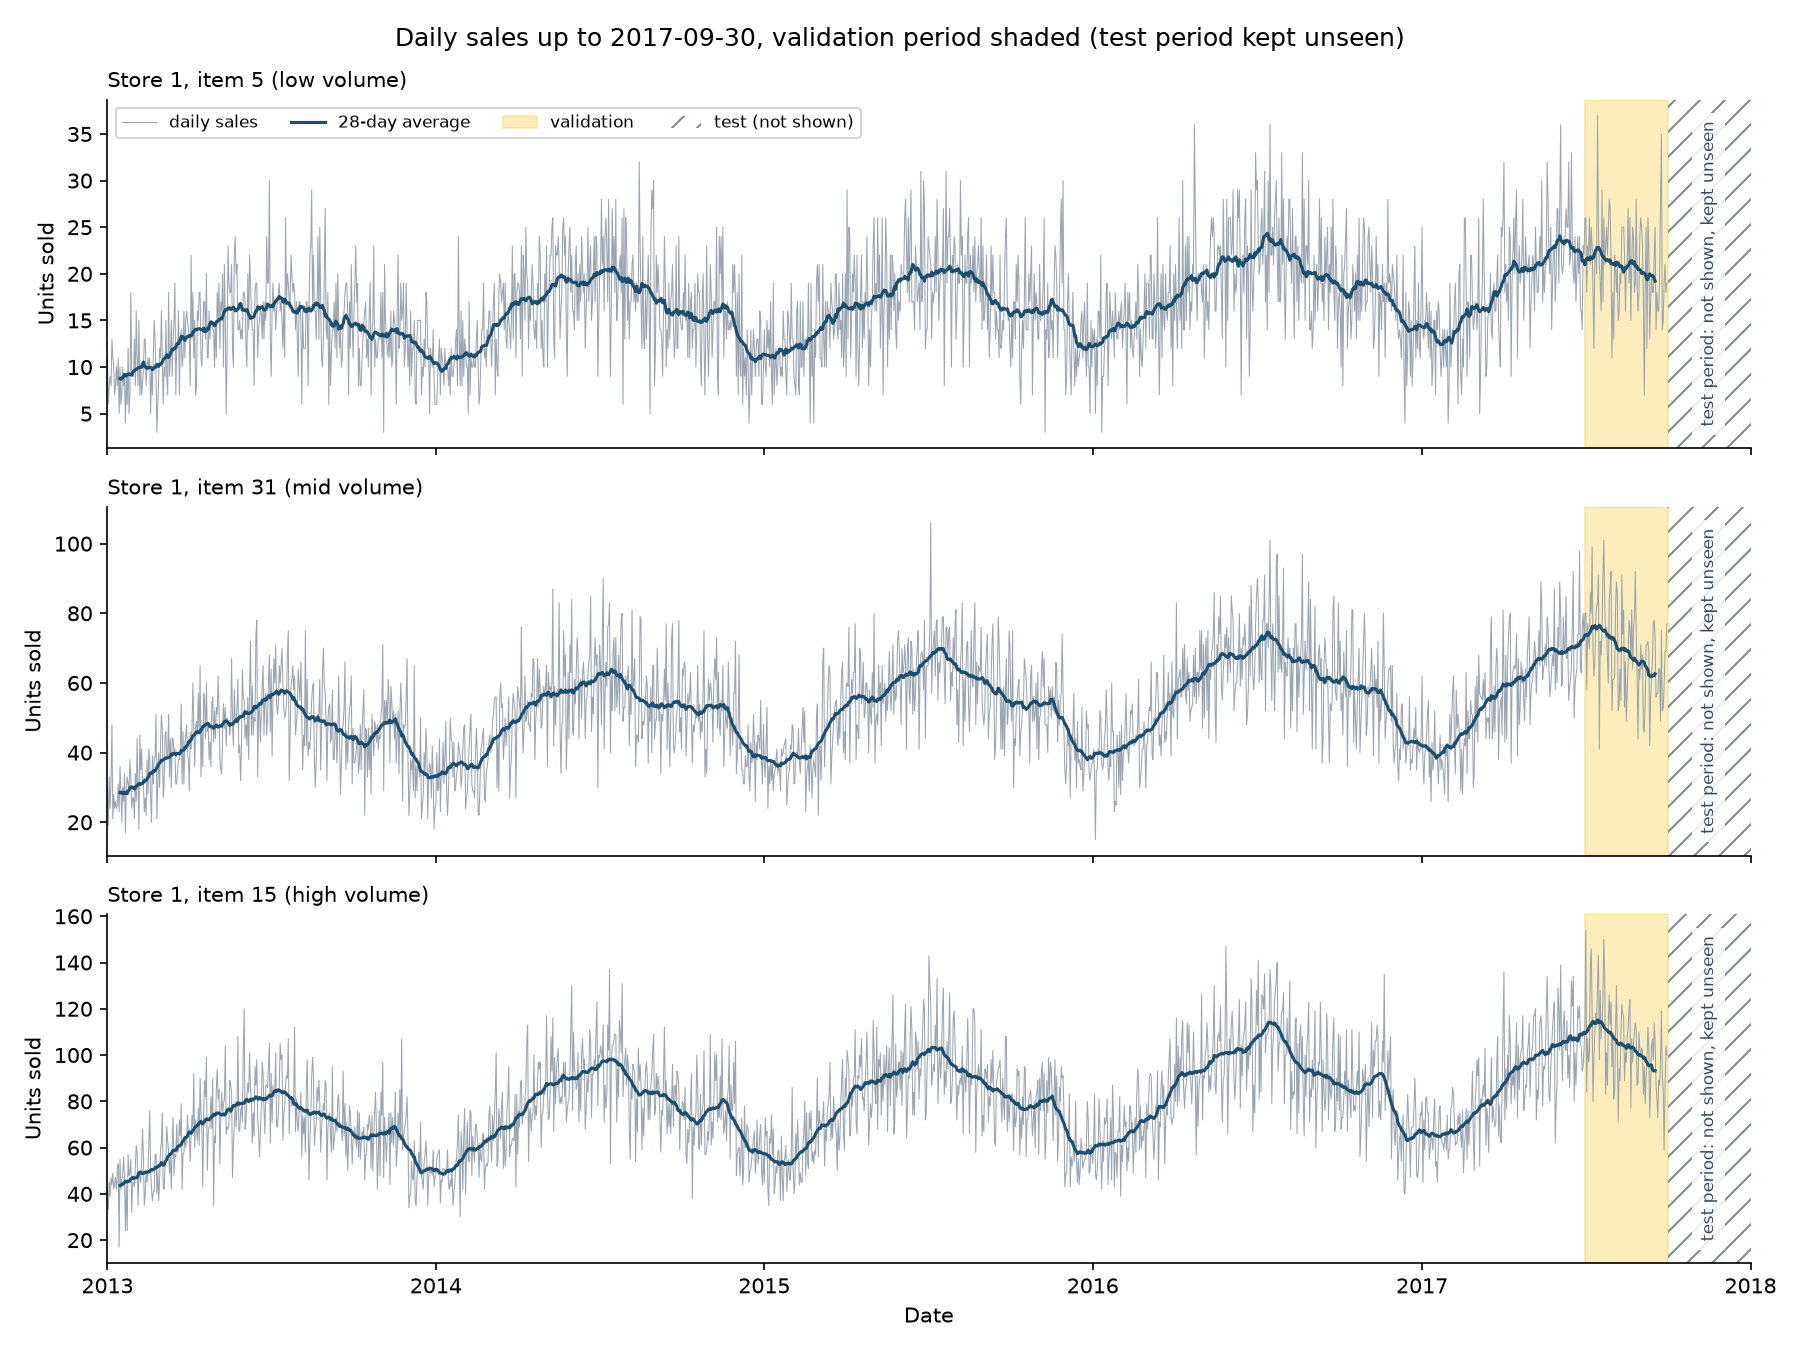

In [8]:
display(Image(filename=str(FIGURES / "eda_series_examples.png"), width=800))

### What the exploration tells us (numbers read from `results/eda_checks.json`)

In [9]:
with open(RESULTS / "eda_checks.json") as f:
    eda = json.load(f)
wk = eda["seasonality_chosen_total"]
print("Mean units per day, 8 chosen items added up, by weekday (training period):")
print({k: round(v) for k, v in wk["mean_by_weekday"].items()})
print(f"Best weekday / worst weekday: {wk['weekday_max_over_min']:.2f}")
tr = eda["trend_chosen_total"]
print("\nUnits per full year (8 items):", tr["total_sales_by_full_year"])
print("Growth versus the year before:", {k: f"{100*v:.1f}%" for k, v in tr["yoy_growth_full_years"].items()})
print(f"Jan to Jun 2017 compared with Jan to Jun 2016: {100*tr['yoy_growth_jan_jun_2017_vs_2016']:.1f}%")
nd = eda["noise_dispersion_store1_train"]
print(f"\nNoise check (about 1.0 means pure counting noise, like rolling dice): "
      f"median {nd['median']:.2f}, range {nd['min']:.2f} to {nd['max']:.2f}")
rg = eda["regularity_train"]["weekday_profile_corr_between_items_store1"]
print(f"Similarity of the weekday shape between items (1.0 = identical): median {rg['median']:.3f}")

Mean units per day, 8 chosen items added up, by weekday (training period):
{'Mon': 298, 'Tue': 348, 'Wed': 349, 'Thu': 373, 'Fri': 397, 'Sat': 422, 'Sun': 450}
Best weekday / worst weekday: 1.51

Units per full year (8 items): {'2013': 116552, '2014': 134545, '2015': 139909, '2016': 152295}
Growth versus the year before: {'2014_vs_2013': '15.4%', '2015_vs_2014': '4.0%', '2016_vs_2015': '8.9%'}
Jan to Jun 2017 compared with Jan to Jun 2016: 3.8%

Noise check (about 1.0 means pure counting noise, like rolling dice): median 1.02, range 0.91 to 1.13
Similarity of the weekday shape between items (1.0 = identical): median 0.996


**What I take from this.**
- **Weekday matters a lot** (Sunday sells about 1.5 times as much as Monday), and so does the **time of year**.
- **There is a trend**: each year sells more than the one before, but not by a constant amount. A rule that only repeats last year will under-forecast.
- **The day-to-day wobble that is left looks like counting noise**, as if each sale were a random draw. No forecast can predict noise, so even a perfect model keeps some error.
- **The patterns look very regular** (almost identical weekday shapes in every item and store). Real shops are messier. This is one reason I think a program generated the data (a hypothesis), and why this project is a prototype.

## 3. Splits, the decision, and the features

**The decision frame.** The owner orders on Monday morning for Monday to Sunday, so for any day of that week I may only use sales dated before that Monday. Sunday's sales are assumed to be known on Monday morning (see section 12).

**Why only "lags" of 7 days or more.** A *lag* is "the sales of the same item some days ago". A lag of 7 days or more always points to a day before the Monday order, while a lag of 1 day (yesterday) may not have been known yet. The leakage test below checks this.

**The features (what a model may look at):**
- the item, the weekday, the month and the day of the year;
- sales 7, 14, 21, 28 and 364 days ago (364 days is the same weekday last year);
- the mean of the four most recent same-weekday sales, and the mean of the 28 days ending 7 days ago.

In [10]:
import features
from features import FEATURES, LAG_DAYS, MIN_LAG, make_features, rolling_mean_lag7

print("Features used by the models:", FEATURES)
print("Lags in days:", LAG_DAYS, "  smallest lag:", MIN_LAG)
print()
print(inspect.getsource(make_features))

Features used by the models: ['item', 'day_of_week', 'month', 'day_of_year', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'lag_364', 'mean_same_weekday_4', 'mean_28_lag7']
Lags in days: [7, 14, 21, 28, 364]   smallest lag: 7

def make_features(df):
    """One row per (item, date): sales target plus features.

    - NaN where history is too short
    """
    out = df[["date", "item", "sales"]].sort_values(["item", "date"]).reset_index(drop=True)
    check_daily_grid(out)
    by_item = out.groupby("item")["sales"]

    # - 364 days = same weekday last year
    for lag in LAG_DAYS:
        out[f"lag_{lag}"] = by_item.shift(lag)

    # - any lag missing: mean missing
    same_weekday = [f"lag_{lag}" for lag in (7, 14, 21, 28)]
    out["mean_same_weekday_4"] = out[same_weekday].mean(axis=1, skipna=False)

    # - days t-34 to t-7
    out["mean_28_lag7"] = by_item.transform(lambda s: rolling_mean_lag7(s, 28))

    # - known in advance; Monday = 0
    out["day_of_week"] = out["date"].dt.day_of_week

## 4. The leakage test: do the features see the future?

**What leakage is.** A forecast "leaks" if it uses information that would not have been available when the order was placed, such as tomorrow's sales. A leaking model looks brilliant in a test and fails in real life.

**What the test does** (`src/test_leakage.py`, run below). For many target weeks it changes all sales from that week's Monday onward (adds 1000, shuffles them or deletes them) and checks that no forecast for that week moves. It also adds a deliberately leaky feature and checks that the test catches it.

**What a pass tells me.** The forecasts appear to use only sales dated before Monday. The test covers many sampled weeks, not every possible case, and never touches the test period.

In [11]:
import io, contextlib
import test_leakage

buffer = io.StringIO()
with contextlib.redirect_stdout(buffer):
    test_leakage.main()
print(buffer.getvalue())
check("all leakage checks passed", "ALL CHECKS PASSED" in buffer.getvalue())

PASS  split dates and weekdays: {'2017-06-30': 'Friday', '2017-07-01': 'Saturday', '2017-09-30': 'Saturday', '2017-10-01': 'Sunday', '2017-12-31': 'Sunday'}
PASS  12 full weeks 2017-07-03 .. 2017-09-24
PASS  13 full weeks 2017-10-02 .. 2017-12-31
PASS  load_scope refuses any cut-off after 2017-09-30 without the guarded run's ticket
PASS  loaded data 2013-01-01 .. 2017-09-30 (no test rows); train 2013-01-01 .. 2017-06-30, validation 2017-07-01 .. 2017-09-30
      caught leaky feature: lag_1 (yesterday)
      caught leaky feature: lag_6 (leaks on Sundays only)
      caught leaky feature: 7-day mean including today
PASS  negative controls: the perturbation test fails on 3 deliberately leaky features
PASS  features unchanged for 8 weeks (all 7 weekdays) when sales from Monday on are +1000, shuffled or deleted; a change in the week before Monday is detected
      latest sales date read by each feature, first validation week, real data (Monday 2017-07-03):
        item                   no s

## 5. Five forecasting methods, compared on validation

**Three simple rules (baselines)** need no fitting. A fancier model has to beat them to be worth it.
- **Same day last week** (lag 7): the sales on that weekday one week before.
- **Mean of the last 4 same weekdays** ("mean4"): the average of that weekday over the last 4 weeks.
- **Same day last year** (lag 364): the sales on that weekday 52 weeks before.

**Two models** (one model for all 8 items; the item is a feature):
- **Ridge regression:** a weighted sum of the features, with a small penalty that keeps the weights from getting extreme.
- **Gradient boosting:** many small decision trees built one after another, each fixing the mistakes of the ones before.

Both use the library's default settings. I only switched off "early stopping", because it would hold out random days from the middle of the training data. The random seed is fixed, and all five methods are scored on the same days.

In [12]:
from forecast import (BASELINES, MODELS, METHODS, RIDGE_PARAMS, HGB_PARAMS, SEED,
                      baseline_forecasts, make_ridge, make_hgb, fit_model, forecast_period)

print("Ridge settings:", RIDGE_PARAMS)
print("Boosting settings:", HGB_PARAMS)
print()
for fn in (baseline_forecasts, make_ridge, make_hgb, fit_model):
    print(inspect.getsource(fn))

Ridge settings: {'alpha': 1.0}
Boosting settings: {'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'early_stopping': False, 'random_state': 0}

def baseline_forecasts(rows):
    """The three baseline forecasts."""
    return {
        "baseline_lag7": rows["lag_7"],                  # - same weekday last week
        "baseline_mean4": rows["mean_same_weekday_4"],   # - last 4 same weekdays
        "baseline_lag364": rows["lag_364"],              # - same weekday last year
    }

def make_ridge():
    """Ridge in a Pipeline: encoder and scaler see training rows only."""
    prep = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), ["item", "day_of_week", "month"]),
        ("scale", StandardScaler(), ["day_of_year"] + SALES_FEATURES),
    ])
    return Pipeline([("prep", prep), ("ridge", Ridge(**RIDGE_PARAMS))])

def make_hgb():
    """Gradient boosting; item as a category."""
    return HistGradientBoostingRegressor(categ

**How I score a forecast** (the functions are imported from `src/forecast.py`, not rewritten here):
- **Daily MAE** (mean absolute error): the average number of units the forecast is off by on a day. A miss of 5 counts 5 whether too high or too low. Smaller is better.
- **SMAPE:** the miss as a percentage of the sales, so a small item and a big item can be compared. 0 is perfect.
- **Weekly MAE:** the average miss on an item's *weekly total*. This matters most for the order, because the owner orders per week.

In [13]:
from forecast import mae, smape, weekly_totals, score
for fn in (mae, smape, weekly_totals):
    print(inspect.getsource(fn))

def mae(actual, forecast):
    """MAE in units."""
    return float(np.mean(np.abs(np.asarray(actual, float) - np.asarray(forecast, float))))

def smape(actual, forecast):
    """SMAPE in percent (0 to 200).

    - per row 2 * |F - A| / (|A| + |F|); both 0 counts as 0
    """
    a = np.asarray(actual, float)
    f = np.asarray(forecast, float)
    denom = np.abs(a) + np.abs(f)
    terms = np.where(denom == 0, 0.0, 2 * np.abs(f - a) / np.where(denom == 0, 1, denom))
    return float(100 * np.mean(terms))

def weekly_totals(table, mondays, methods=METHODS):
    """Weekly sums per item (full Mon to Sun weeks)."""
    week_start = table["date"] - pd.to_timedelta(table["date"].dt.day_of_week, unit="D")
    in_full_week = week_start.isin(mondays)
    weeks = table.loc[in_full_week].assign(week_monday=week_start[in_full_week])
    grouped = weeks.groupby(["item", "week_monday"])
    require((grouped.size() == 7).all(), "a full week must have 7 days")
    return grouped[["actual"] + list(meth

### Fitting on the training period and forecasting the validation period
This step trains both models on data up to 2017-06-30 and forecasts every day from 2017-07-01 to 2017-09-30 (8 items x 92 days = 736 forecasts per method). It writes no file. Then it checks that the result is the same as the saved validation file.

In [14]:
from run_validation import build_validation_predictions
val_table, val_feats, val_models = build_validation_predictions()

saved = pd.read_csv(RESULTS / "validation_predictions.csv", parse_dates=["date"])
same_rows = len(saved) == len(val_table) == 736
close = same_rows and np.allclose(saved[["actual"] + METHODS].to_numpy(),
                                  val_table[["actual"] + METHODS].round(4).to_numpy(), atol=1e-3)
check("736 validation forecasts per method, same rows for all methods", same_rows and val_table[METHODS].notna().all().all())
check("recomputed forecasts equal results/validation_predictions.csv", bool(close))
val_scores = score(val_table, VAL_WEEK_MONDAYS)
with open(RESULTS / "validation_metrics.json") as f:
    saved_metrics = json.load(f)
check("recomputed scores equal results/validation_metrics.json",
      all(abs(val_scores["overall"][m][k] - saved_metrics["overall"][m][k]) < 1e-9
          for m in METHODS for k in ("mae", "smape", "weekly_mae")))

PASS  736 validation forecasts per method, same rows for all methods
PASS  recomputed forecasts equal results/validation_predictions.csv
PASS  recomputed scores equal results/validation_metrics.json


**Names and the scoring table.** Defines short names for the five methods and a helper that lays the three scores (daily MAE, SMAPE, weekly MAE) out as a table, then prints the validation scores of all five methods.

In [15]:
NAMES = {
    "baseline_lag7": "Same day last week (lag 7)",
    "baseline_mean4": "Mean of last 4 same weekdays",
    "baseline_lag364": "Same day last year (lag 364)",
    "ridge": "Ridge regression",
    "hgb": "Gradient boosting",
}

SHORT = {"baseline_lag7": "lag 7", "baseline_mean4": "mean4", "baseline_lag364": "lag 364",
         "ridge": "Ridge", "hgb": "Boosting"}

def overall_table(scores):
    t = pd.DataFrame(scores["overall"]).T.loc[METHODS]
    t.index = [NAMES[m] for m in t.index]
    t.columns = ["daily MAE (units)", "SMAPE (%)", "weekly MAE (units)"]
    return t

print("Validation, 2017-07-01 to 2017-09-30 (736 days, 96 item-weeks):")
display(overall_table(val_scores).round(2))

Validation, 2017-07-01 to 2017-09-30 (736 days, 96 item-weeks):


,daily MAE (units),SMAPE (%),weekly MAE (units)
Same day last week (lag 7),8.83,15.89,26.46
Mean of last 4 same weekdays,7.58,13.41,28.36
Same day last year (lag 364),8.83,16.19,25.43
Ridge regression,6.52,12.07,20.95
Gradient boosting,6.63,12.00,19.86


**Reading the table.** Lower is better in every column. The three simple rules have larger errors than the two models, and the two models are close to each other: Ridge is slightly ahead on daily MAE, boosting is slightly ahead on SMAPE and on weekly totals. Section 7 comes back to this tie. As a sanity check, the models' error on their own training data is printed below. It is lower than on validation, as expected, and not absurdly low.

In [16]:
print("In-sample (training) daily MAE:", {m: round(v, 2) for m, v in saved_metrics["train_in_sample_mae"].items()})
print()
print("Daily MAE per item (validation):")
per_item_mae = pd.DataFrame({m: {i: v[m]["mae"] for i, v in val_scores["per_item"].items()} for m in METHODS})
per_item_mae.columns = [SHORT[m] for m in METHODS]
per_item_mae.index.name = "item"
display(per_item_mae.round(2))
print("Weekly MAE per item (validation):")
per_item_week = pd.DataFrame({m: {i: v[m]["weekly_mae"] for i, v in val_scores["per_item"].items()} for m in METHODS})
per_item_week.columns = [SHORT[m] for m in METHODS]
per_item_week.index.name = "item"
display(per_item_week.round(1))

In-sample (training) daily MAE: {'ridge': 5.95, 'hgb': 4.91}

Daily MAE per item (validation):


,lag 7,mean4,lag 364,Ridge,Boosting
item,,,,,
5,4.41,3.58,4.64,3.80,3.24
15,12.49,10.67,12.17,9.07,9.35
16,6.41,5.34,5.35,4.61,4.81
20,10.12,8.83,9.68,7.52,7.95
25,10.83,9.77,11.03,7.92,8.40
31,9.39,7.52,10.18,6.57,6.42
33,10.61,9.67,10.42,7.56,7.98
42,6.40,5.23,7.14,5.07,4.89


Weekly MAE per item (validation):


,lag 7,mean4,lag 364,Ridge,Boosting
item,,,,,
5,13.8,9.9,14.3,16.8,10.3
15,35.8,45.2,40.0,29.4,30.5
16,16.3,13.3,20.5,13.9,12.4
20,27.6,30.9,21.3,24.3,27.8
25,23.1,36.3,26.3,17.3,15.1
31,31.8,37.2,25.0,20.3,21.6
33,45.3,39.7,36.4,27.6,28.2
42,17.8,14.3,19.5,17.9,12.8


Items are listed by item number (item 5 is the smallest seller, item 15 the largest). Errors grow with item size, which is natural: bigger numbers have bigger counting noise. The best method is not the same for every item (compare the columns row by row).

## 6. From forecasts to orders to costs (the order simulation, validation period)

**The ordering rule.** For every item and every full Monday-to-Sunday week, I add up the 7 daily forecasts, multiply by `(1 + buffer)` (the **buffer** is a safety margin in percent, for example +5%), round to a whole number of units (the **order**) and compare it with what was really sold that week.

**The cost.** Every unit the shop is **short** costs `C_SHORT = 3`, and every unit **left over** costs `C_OVER = 1` (cost units). **The 3 : 1 ratio is an assumption, not a measured number**: I assume that a lost sale and an unhappy customer hurt about three times as much as a leftover unit. I also test 1 : 1 and 5 : 1. The simplifications (weekly totals only, no carry-over of leftovers) are listed in section 12.

In [17]:
import simulate
from simulate import (C_SHORT, C_OVER, COST_RATIOS, HEADLINE_RATIO, BUFFER_GRID, ROUNDING_RULE,
                      round_order, order_quantity, shortfall, leftover, order_cost, tune_buffer)

print(f"C_SHORT = {C_SHORT}, C_OVER = {C_OVER}   (an assumption)   ratios tested: {list(COST_RATIOS)}")
print("Rounding rule:", ROUNDING_RULE, "\n")
for fn in (order_quantity, shortfall, leftover, order_cost):
    print(inspect.getsource(fn))

C_SHORT = 3, C_OVER = 1   (an assumption)   ratios tested: ['1:1', '3:1', '5:1']
Rounding rule: order = (sum of the 7 daily forecasts) x (1 + buffer), rounded to the nearest whole unit, an exact half rounded up (120.5 -> 121). Computed as floor(x + 0.5 + 1e-9): the tiny 1e-9 stops computer rounding noise (120.49999999999999) from turning a true half down. 

def order_quantity(weekly_forecast, buffer):
    """Weekly forecast x (1 + buffer), rounded, at least 0."""
    raw = np.asarray(weekly_forecast, dtype=float) * (1 + buffer)
    return np.maximum(round_order(raw), 0)

def shortfall(actual, order):
    """Units short (demand above order)."""
    return np.maximum(np.asarray(actual) - np.asarray(order), 0)

def leftover(actual, order):
    """Units left over (order above demand)."""
    return np.maximum(np.asarray(order) - np.asarray(actual), 0)

def order_cost(actual, order, c_short, c_over):
    """c_short x short + c_over x left over."""
    return c_short * shortfall(actual, orde

### One worked example
I take the first item-week of the validation table (item 5, the week starting Monday 2017-07-03) and price the order of every method with **no buffer**, so you can follow the arithmetic by hand.

In [18]:
from run_simulation_validation import load_validation_predictions
from simulate import weekly_table, simulate_method

val_daily = load_validation_predictions()          # - read only
val_weekly = weekly_table(val_daily, VAL_WEEK_MONDAYS)
check("96 validation item-weeks (12 weeks x 8 items)", len(val_weekly) == 96)

first = val_weekly.iloc[:1]
rows = []
for m in METHODS:
    s = simulate_method(first, m, 0.0, C_SHORT, C_OVER).iloc[0]
    rows.append({"method": NAMES[m], "week total forecast": round(s["forecast"], 1), "order": int(s["order"]),
                 "actually sold": int(s["actual"]), "units short": int(s["short"]),
                 "units left over": int(s["over"]), "cost (3:1)": int(s["cost"])})
print(f"Item {int(first['item'].iloc[0])}, week starting {first['week_monday'].iloc[0].date()}")
display(pd.DataFrame(rows).set_index("method"))

PASS  96 validation item-weeks (12 weeks x 8 items)
Item 5, week starting 2017-07-03


,week total forecast,order,actually sold,units short,units left over,cost (3:1)
method,,,,,,
Same day last week (lag 7),143.0,143,158,15,0,45
Mean of last 4 same weekdays,157.2,157,158,1,0,3
Same day last year (lag 364),169.0,169,158,0,11,11
Ridge regression,182.8,183,158,0,25,25
Gradient boosting,164.7,165,158,0,7,7


### Tuning the safety buffer (validation only)
A forecast that is too low on average needs a positive buffer; one that is too high needs a negative buffer. **Every method gets its own buffer**, including the three simple rules, so a biased rule can correct itself and the comparison stays fair. For each method and each cost ratio I try every buffer from -20% to +40% in steps of one percentage point and keep the cheapest one on the 12 validation weeks. I also report **buffer 0** (order exactly the forecast), which needs no tuning.

The cell checks that these buffers match the ones saved before the test in `results/buffers.json`. Nothing is written.

In [19]:
from simulate import tune_all, best_baselines, build_tables, load_buffers
from headline import load_headline_record

print(inspect.getsource(tune_buffer))
headline_record = load_headline_record()
HEAD = headline_record["headline_model"]
OTHER = headline_record["other_model"]

val_buffers, val_curves = tune_all(val_weekly)
val_best = best_baselines(val_weekly, val_buffers)
val_result, val_long = build_tables(val_weekly, val_buffers, val_best, HEAD)

frozen = load_buffers()
check("recomputed buffers equal the frozen results/buffers.json", val_buffers == frozen["buffers"])
check("recomputed best baselines equal the frozen ones", val_best == frozen["best_baseline"])
with open(RESULTS / "simulation_validation.json") as f:
    saved_sim = json.load(f)
check("recomputed validation costs equal results/simulation_validation.json",
      json.loads(json.dumps(val_result["results"])) == saved_sim["results"])

buf = pd.DataFrame(val_buffers).loc[METHODS]
buf.index = [NAMES[m] for m in buf.index]
print("Tuned buffers (fraction added to the weekly forecast; 0.05 = +5%):")
display(buf)

def tune_buffer(weekly, method, c_short, c_over, grid=BUFFER_GRID):
    """Cheapest buffer on the grid (ties: TIE_BREAK_RULE).

    - returns (best buffer, {buffer: cost})
    """
    assert_validation_only(weekly)
    costs = {b: total_cost(weekly, method, b, c_short, c_over) for b in grid}
    best = min(grid, key=lambda b: (costs[b], abs(b), b))
    return best, costs



PASS  recomputed buffers equal the frozen results/buffers.json
PASS  recomputed best baselines equal the frozen ones
PASS  recomputed validation costs equal results/simulation_validation.json
Tuned buffers (fraction added to the weekly forecast; 0.05 = +5%):


,1:1,3:1,5:1
Same day last week (lag 7),-0.01,0.04,0.05
Mean of last 4 same weekdays,-0.04,0.02,0.05
Same day last year (lag 364),0.03,0.08,0.10
Ridge regression,0.00,0.04,0.06
Gradient boosting,0.01,0.04,0.06


**Cost against buffer.** For each method this plots the total validation cost for every buffer from -20% to +40%; the dot is the cheapest point. It is a picture of the table-making step above.

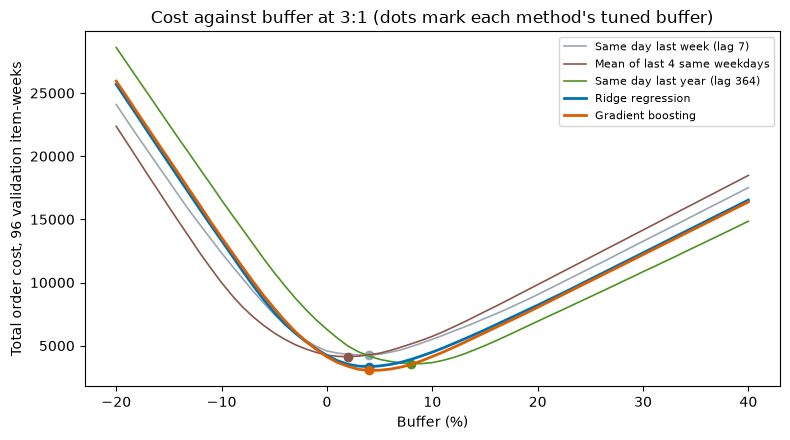

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"baseline_lag7": "#9aa5b1", "baseline_mean4": "#8c564b", "baseline_lag364": "#4d9221",
          "ridge": "#0072b2", "hgb": "#d95f02"}
for m in METHODS:
    xs = [float(b) for b in val_curves[HEADLINE_RATIO][m]]
    ax.plot([100 * x for x in xs], list(val_curves[HEADLINE_RATIO][m].values()), label=NAMES[m], color=colors[m], lw=2 if m in MODELS else 1.2)
    ax.plot(100 * val_buffers[HEADLINE_RATIO][m], min(val_curves[HEADLINE_RATIO][m].values()), "o", color=colors[m])
ax.set_xlabel("Buffer (%)")
ax.set_ylabel("Total order cost, 96 validation item-weeks")
ax.set_title("Cost against buffer at 3:1 (dots mark each method's tuned buffer)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Reading the curves.** Each curve dips to a lowest point. The dots show the tuned buffers. A good forecast has a
deep, narrow dip near zero. A biased rule has its dip far from zero.

In [21]:
def cost_table(result, ratio):
    t = pd.DataFrame({
        "buffer": {m: result["results"][ratio]["tuned_buffer"][m]["buffer"] for m in METHODS},
        "cost, tuned buffer": {m: result["results"][ratio]["tuned_buffer"][m]["total_cost"] for m in METHODS},
        "cost, buffer 0": {m: result["results"][ratio]["zero_buffer"][m]["total_cost"] for m in METHODS},
        "units short (tuned)": {m: result["results"][ratio]["tuned_buffer"][m]["short_units"] for m in METHODS},
        "units left over (tuned)": {m: result["results"][ratio]["tuned_buffer"][m]["over_units"] for m in METHODS},
    })
    t.index = [NAMES[m] for m in t.index]
    return t

print("VALIDATION order cost at the default ratio 3:1 (lower is better; in-sample, see the note below):")
display(cost_table(val_result, HEADLINE_RATIO))

VALIDATION order cost at the default ratio 3:1 (lower is better; in-sample, see the note below):


,buffer,"cost, tuned buffer","cost, buffer 0",units short (tuned),units left over (tuned)
Same day last week (lag 7),0.04,4245,4580,510,2715
Mean of last 4 same weekdays,0.02,4127,4251,518,2573
Same day last year (lag 364),0.08,3575,6289,433,2276
Ridge regression,0.04,3342,4221,467,1941
Gradient boosting,0.04,3048,4121,423,1779


**Sensitivity to the cost assumption.** The same table for 1 : 1 and 5 : 1. If the ranking of the methods changed a lot with the assumed ratio, the conclusions would depend too much on a number I made up.

In [22]:
sens = pd.DataFrame(val_result["sensitivity"])
view = sens.pivot_table(index="method", columns=["cost_ratio", "setting"], values="total_cost").loc[METHODS]
view.index = [NAMES[m] for m in view.index]
view = view[[(r, s) for r in COST_RATIOS for s in ("tuned_buffer", "zero_buffer")]]
print("VALIDATION total cost for every cost ratio, with tuned buffer and with buffer 0:")
display(view)

per_item = pd.DataFrame({m: val_result["results"][HEADLINE_RATIO]["tuned_buffer"][m]["cost_per_item"] for m in METHODS})
per_item.columns = [SHORT[m] for m in METHODS]
per_item.index.name = "item"
print("VALIDATION cost per item at 3:1, tuned buffers:")
display(per_item)

VALIDATION total cost for every cost ratio, with tuned buffer and with buffer 0:


cost_ratio                            1:1                      3:1                      5:1            
setting                      tuned_buffer zero_buffer tuned_buffer zero_buffer tuned_buffer zero_buffer
Same day last week (lag 7)         2508.0      2540.0       4245.0      4580.0       5167.0      6620.0
Mean of last 4 same weekdays       2482.0      2727.0       4127.0      4251.0       4940.0      5775.0
Same day last year (lag 364)       2159.0      2441.0       3575.0      6289.0       4161.0     10137.0
Ridge regression                   2011.0      2011.0       3342.0      4221.0       4108.0      6431.0
Gradient boosting                  1892.0      1907.0       3048.0      4121.0       3621.0      6335.0

VALIDATION cost per item at 3:1, tuned buffers:


,lag 7,mean4,lag 364,Ridge,Boosting
item,,,,,
5,274,177,332,332,178
15,611,855,633,482,515
16,348,230,401,297,247
20,537,555,567,575,608
25,683,701,483,339,256
31,651,663,371,439,419
33,829,718,393,542,600
42,312,228,395,336,225


### How sure are we? (uncertainty, still validation)
There are only 12 validation weeks, so a cost difference between two methods can be luck. To see how much, I use a **bootstrap interval**: I take the weekly cost difference between a model and the best simple rule, re-draw the 12 weeks at random 10,000 times and see how much the total difference moves. The 95% interval is the middle 95% of those totals. If it contains 0, the data cannot tell the two apart. Negative means the model is cheaper.

The table also has a **leave-one-week-out** cost (the buffer is chosen without the week it is scored on, which shows how optimistic the tuned costs are) and the number of weeks in which the model was cheaper.

In [23]:
rows = []
for ratio in COST_RATIOS:
    for m in MODELS:
        u = val_result["uncertainty"][ratio]["tuned_buffer"][m]
        rows.append({"cost ratio": ratio, "model": NAMES[m], "vs best baseline": NAMES[u["baseline"]],
                     "model cost": u["model_total"], "baseline cost": u["baseline_total"],
                     "difference": round(u["total_difference"]), "95% interval": f"{u['ci95_low']:.0f} to {u['ci95_high']:.0f}",
                     "weeks model cheaper": f"{u['weeks_a_cheaper']} of {u['n_weeks']}"})
print("VALIDATION, tuned buffers, model minus best baseline (negative = model cheaper):")
display(pd.DataFrame(rows))

lowo = saved_sim["leave_one_week_out_check"][HEADLINE_RATIO]
t = pd.DataFrame({"tuned cost (in-sample)": {m: lowo[m]["tuned_cost_in_sample"] for m in METHODS},
                  "leave-one-week-out cost": {m: lowo[m]["leave_one_week_out_cost"] for m in METHODS}})
t.index = [NAMES[m] for m in t.index]
print("Optimism check at 3:1 (read from results/simulation_validation.json):")
display(t)

VALIDATION, tuned buffers, model minus best baseline (negative = model cheaper):


,cost ratio,model,vs best baseline,model cost,baseline cost,difference,95% interval,weeks model cheaper
0,1:1,Ridge regression,Same day last year (lag 364),2011,2159,-148,-580 to 280,7 of 12
1,1:1,Gradient boosting,Same day last year (lag 364),1892,2159,-267,-627 to 73,6 of 12
2,3:1,Ridge regression,Same day last year (lag 364),3342,3575,-233,-896 to 497,7 of 12
3,3:1,Gradient boosting,Same day last year (lag 364),3048,3575,-527,-1156 to 169,8 of 12
4,5:1,Ridge regression,Same day last year (lag 364),4108,4161,-53,-889 to 909,7 of 12
5,5:1,Gradient boosting,Same day last year (lag 364),3621,4161,-540,-1289 to 298,8 of 12


Optimism check at 3:1 (read from results/simulation_validation.json):


,tuned cost (in-sample),leave-one-week-out cost
Same day last week (lag 7),4245,4493
Mean of last 4 same weekdays,4127,4328
Same day last year (lag 364),3575,3708
Ridge regression,3342,3342
Gradient boosting,3048,3191


**Reading the validation costs.**
- The tuned costs are **in-sample**: the buffer was picked on the same 12 weeks it is scored on, so they look better than a real owner could have achieved. The leave-one-week-out column shows by how much.
- With tuned buffers both models have the lowest cost at all three ratios, but every 95% interval against the best simple rule includes 0. With no buffer, the simple rule "mean4" is cheaper than both models at 5 : 1. So validation alone cannot show that a model beats a good simple rule. That is why the test, on data nobody tuned on, is the real comparison.

## 7. What was fixed before the test

Up to here I looked at validation numbers and made choices. Before the test I wrote down every choice and fixed it. After the test I change nothing, whatever the results say.

### The main model
The main model is **gradient boosting**. I decided this after looking at validation results:
- My first rule was "the model with the lowest daily MAE". On validation that picks **Ridge**, by a tiny margin.
- What matters to the owner is the weekly **order cost**, and there boosting is cheaper on validation. So I switched the rule to "lowest order cost at 3 : 1 with tuned buffers", which picks boosting.
- The test period was not read for this choice, but I made it after seeing validation numbers, so I say so here. Ridge stays in every table next to boosting.

The exact record is in `results/headline_model.json`:

In [24]:
print("Headline model:", headline_record["headline_model_name"], f"(code name '{HEAD}')")
print("Other model, always reported next to it:", OTHER)
print("Rule:", headline_record["rule"])
print("Earlier rule replaced:", headline_record["earlier_rule_replaced"])
print("Decided by:", headline_record["decided_by"], "on", headline_record["decided_on"])
print("\nDisclosure lines stored with the decision:")
for line in headline_record["disclosure"]:
    print(" -", line)

Headline model: gradient boosting (sklearn HistGradientBoostingRegressor) (code name 'hgb')
Other model, always reported next to it: ridge
Rule: lowest total order cost on the 96 validation item-weeks at the default cost ratio 3:1 (short 3 : over 1), each model with its own buffer tuned on validation
Earlier rule replaced: lowest overall daily MAE on validation (fixed in advance in task 03); it picked ridge (6.516 vs hgb 6.630)
Decided by: user decision D8 in PLAN.md, before any test-period data was read on 2026-11-14

Disclosure lines stored with the decision:
 - Ridge is marginally ahead on daily MAE on validation (6.52 vs 6.63 units per day).
 - The selection rule was changed from daily MAE to order cost after seeing the validation results. Only validation data was used for this; the test period (2017-10-01 onward) was not read, predicted or scored when the decision was made.
 - Both models are reported side by side everywhere; Ridge is never dropped from a table.
 - The validation 

### Buffers and comparison baselines, fixed from validation
The tuned buffers were saved in `results/buffers.json` before the test (shown in section 6). The test run only **reads** them. The **comparison baselines** are fixed now too, so I cannot pick the most flattering baseline after seeing the test:

In [25]:
fixed = headline_record["comparison_baselines_fixed_from_validation"]
rows = []
for ratio in COST_RATIOS:
    for setting in ("tuned_buffer", "zero_buffer"):
        rows.append({"measure": f"order cost {ratio}, {setting.replace('_', ' ')}", "pre-fixed best baseline": NAMES[fixed["order_cost"][ratio][setting]]})
for label, key in (("daily MAE", "daily_mae"), ("SMAPE", "smape"), ("weekly MAE", "weekly_mae")):
    rows.append({"measure": label, "pre-fixed best baseline": NAMES[fixed[key]]})
display(pd.DataFrame(rows).set_index("measure"))
print(fixed["note"])

,pre-fixed best baseline
measure,
"order cost 1:1, tuned buffer",Same day last year (lag 364)
"order cost 1:1, zero buffer",Same day last year (lag 364)
"order cost 3:1, tuned buffer",Same day last year (lag 364)
"order cost 3:1, zero buffer",Mean of last 4 same weekdays
"order cost 5:1, tuned buffer",Same day last year (lag 364)
"order cost 5:1, zero buffer",Mean of last 4 same weekdays
daily MAE,Mean of last 4 same weekdays
SMAPE,Mean of last 4 same weekdays
weekly MAE,Same day last year (lag 364)


Fixed on validation before the test run, so the test tables cannot pick the comparison after seeing test results. All baselines are still reported.


### Every choice made after looking at training or validation numbers
Here is the complete list (none of it used test data):
1. **Scope:** store 1 and 8 items spaced evenly by volume, by a rule written down before the run (training data only).
2. **Splits and cost ratios:** set in advance (3 : 1, with 1 : 1 and 5 : 1 as checks).
3. **Features:** the planned set. Three extra features were tried on validation and dropped (the details of this check were not saved).
4. **Settings:** library defaults, no search. Only boosting's early stopping was switched off.
5. **Main model:** switched from Ridge (lowest daily MAE) to boosting (lowest order cost) after seeing validation.
6. **Buffer design:** one buffer per method and ratio, every baseline tuned too, grid -20% to +40%. I added the negative range after a validation check showed that "mean4" over-forecasts after the July peak.
7. **Buffers and best baselines:** tuned on the same 12 validation weeks they are scored on (in-sample, optimistic).
8. **Failure analysis:** the rules (what counts as a bad day, which example is shown, which tests are run) were developed on validation and fixed before I applied them to the test.
9. **An early figure** showed Oct to Dec 2017 sales, and I saw it once during data exploration, before modelling. I replaced it (Figure 4 no longer shows them). Nothing was tuned on it and no choice used it.

### Fingerprints of the fixed files
A fingerprint is a short code made from a file: if the file changes, the code changes. The next cell prints the first 16 characters of the fingerprint (SHA-256) of each of the 17 fixed files (code, saved results, the data file and the library list). It also shows the run log as it stood before the final-run cell below runs. The guard writes that log (section 8), and each entry stores a code made from the entry before it, so changing the history would show.

In [26]:
from run_final_test import hash_frozen_inputs, status, changed_since_first_run, run_final_test
fp = hash_frozen_inputs()
display(pd.DataFrame({"SHA-256 (first 16 characters)": {k: (v or "MISSING")[:16] for k, v in fp.items()}}))
check("all 17 frozen files exist", len(fp) == 17 and all(v is not None for v in fp.values()))
print("Run log before the final cell:")
print(status())

,SHA-256 (first 16 characters)
results/scope.json,B49F56A661AFD8F9
results/buffers.json,1506264A61EE7C6B
results/headline_model.json,9A8483E31E4C1388
results/validation_metrics.json,7978CD607952481C
results/validation_predictions.csv,FCC750487A7DBF15
src/data_prep.py,7C3FEA9B60AABD04
src/features.py,A1D96265CC82D532
src/forecast.py,6F1AA3D6CE53AC06
src/simulate.py,D266C2A47322B3F2
src/guard.py,381470696037C6A5


PASS  all 17 frozen files exist
Run log before the final cell:
  1  2026-11-15T20:45:52  started         run 1
  2  2026-11-15T20:45:53  finished        run 1
fingerprint of the last log entry (record it outside the project): 01291F0E396B46D1619764FB11300CB1A5572CBB15C3195FDA208FE39F74F15E


## 8. The final test run (guarded)

The next cell is the only cell in this notebook that loads the test period (2017-10-01 to 2017-12-31). I fixed every choice before using the test period for evaluation. The one exception is the early figure of Oct to Dec 2017 sales that I saw once during data exploration, before modelling (section 7), and nothing was tuned on it.

**What the guard does** (`src/run_final_test.py`): before reading any test data it checks the fingerprints of the 17 fixed files and writes a "started" line in the run log. It then refits the models, writes the four test output files and a "finished" line, and on a re-run checks that the new outputs are identical to the first run's. The guard stops accidents, not cheating.

After the results were final, the comments were shortened and tidied, four messages were reworded and `scipy` was pinned in `requirements.txt`; no logic changed, the run log was restarted, and the results are identical to before. `results/final_test_log.json` shows the first run and later re-runs, each verified as identical.

In [27]:
# - guarded final test run; fresh kernel, one process
final = run_final_test(confirm=True)

print()
print(status())
print("Frozen inputs or outputs changed since the first run:", changed_since_first_run())
test_pred, test_metrics = final["predictions"], final["metrics"]
test_costs, test_cost_table = final["costs"], final["cost_table"]
check("headline model in the test result is the frozen one", test_metrics["headline_model"] == HEAD)
check("736 test forecasts (8 items x 92 days), five methods, same rows",
      len(test_pred) == 736 and test_pred[METHODS].notna().all().all())
print(f"Test period: {test_pred['date'].min().date()} to {test_pred['date'].max().date()}, "
      f"fitted on: {test_metrics['fitted_on']}")

Final test run 2 logged. Fingerprint of the last log entry (keep a copy outside the project): 1EC390E487C933230DEBA49E01FB2166988012A3862B24E68ABAB7B5D99AC43A

  1  2026-11-15T20:45:52  started         run 1
  2  2026-11-15T20:45:53  finished        run 1
  3  2026-11-15T20:47:06  started         run 2
  4  2026-11-15T20:47:07  finished        run 2
fingerprint of the last log entry (record it outside the project): 1EC390E487C933230DEBA49E01FB2166988012A3862B24E68ABAB7B5D99AC43A
Frozen inputs or outputs changed since the first run: ([], [])
PASS  headline model in the test result is the frozen one
PASS  736 test forecasts (8 items x 92 days), five methods, same rows
Test period: 2017-10-01 to 2017-12-31, fitted on: start of data .. 2017-09-30 (train + validation), frozen settings


## 9. Test results: how close are the forecasts?

Same three measures as on validation, for all five methods, on the 736 test days (daily MAE and SMAPE) and the 104 test item-weeks (weekly MAE). The numbers below are read from what the guarded run returned. Nothing was changed after seeing them.

In [28]:
print("TEST, 2017-10-01 to 2017-12-31 (lower is better in every column):")
test_table = overall_table(test_metrics)
display(test_table.round(2))
lowest = {col: test_table[col].idxmin() for col in test_table.columns}
print("Lowest value in each column:", lowest)

TEST, 2017-10-01 to 2017-12-31 (lower is better in every column):


,daily MAE (units),SMAPE (%),weekly MAE (units)
Same day last week (lag 7),8.68,19.81,24.76
Mean of last 4 same weekdays,8.14,18.17,34.33
Same day last year (lag 364),8.14,19.12,26.45
Ridge regression,6.38,16.16,21.85
Gradient boosting,6.18,14.36,18.09


Lowest value in each column: {'daily MAE (units)': 'Gradient boosting', 'SMAPE (%)': 'Gradient boosting', 'weekly MAE (units)': 'Gradient boosting'}


**Test scores per item.** The same three measures for each of the 8 items, with the best method marked in each row. This shows whether the overall winner also wins item by item.

In [29]:
print("Daily MAE per item (test):")
t_item_mae = pd.DataFrame({m: {i: v[m]["mae"] for i, v in test_metrics["per_item"].items()} for m in METHODS})
t_item_mae.columns = [SHORT[m] for m in METHODS]
t_item_mae.index.name = "item"
t_item_mae["best method"] = t_item_mae.idxmin(axis=1)
display(t_item_mae.round(2))
print("Weekly MAE per item (test):")
t_item_wk = pd.DataFrame({m: {i: v[m]["weekly_mae"] for i, v in test_metrics["per_item"].items()} for m in METHODS})
t_item_wk.columns = [SHORT[m] for m in METHODS]
t_item_wk.index.name = "item"
t_item_wk["best method"] = t_item_wk.idxmin(axis=1)
display(t_item_wk.round(1))
print("SMAPE (%) per item (test):")
t_item_sm = pd.DataFrame({m: {i: v[m]["smape"] for i, v in test_metrics["per_item"].items()} for m in METHODS})
t_item_sm.columns = [SHORT[m] for m in METHODS]
t_item_sm.index.name = "item"
t_item_sm["best method"] = t_item_sm.idxmin(axis=1)
display(t_item_sm.round(1))

Daily MAE per item (test):


,lag 7,mean4,lag 364,Ridge,Boosting,best method
item,,,,,,
5,4.63,4.17,4.49,4.27,3.32,Boosting
15,11.00,11.34,11.33,8.04,8.17,Ridge
16,6.82,5.91,6.40,5.39,4.98,Boosting
20,8.88,7.41,7.61,6.01,5.78,Boosting
25,11.63,10.83,10.40,8.40,8.17,Boosting
31,9.34,8.77,8.42,6.67,6.56,Boosting
33,10.25,9.48,9.76,7.36,7.34,Boosting
42,6.92,7.21,6.71,4.93,5.10,Ridge


Weekly MAE per item (test):


,lag 7,mean4,lag 364,Ridge,Boosting,best method
item,,,,,,
5,15.6,13.1,11.2,17.2,8.1,Boosting
15,26.5,54.8,39.8,27.2,22.1,Boosting
16,13.0,18.8,13.5,18.0,9.2,Boosting
20,27.0,28.6,27.3,22.5,19.0,Boosting
25,35.8,50.9,27.7,29.6,25.3,Boosting
31,25.9,40.8,30.3,22.1,22.1,Boosting
33,29.0,37.2,36.3,22.5,21.5,Boosting
42,25.2,30.5,25.5,15.6,17.5,Ridge


SMAPE (%) per item (test):


,lag 7,mean4,lag 364,Ridge,Boosting,best method
item,,,,,,
5,27.4,24.6,27.4,31.1,20.2,Boosting
15,13.5,13.5,14.4,9.8,10.1,Ridge
16,29.1,24.8,27.8,24.4,21.3,Boosting
20,19.9,16.7,17.9,14.0,13.3,Boosting
25,15.6,14.2,14.3,11.2,11.0,Boosting
31,16.8,15.8,15.3,12.2,11.9,Boosting
33,15.6,14.3,15.7,11.4,11.5,Ridge
42,20.5,21.5,20.2,15.1,15.6,Ridge


### Main model against the baseline fixed in advance
The comparison baselines fixed in advance (see section 7) are "mean of last 4 same weekdays" for daily MAE and SMAPE, and "same day last year" for weekly MAE. For each measure I print both numbers. A negative difference means the model is better (lower error).

In [30]:
vs = test_metrics["models_vs_baseline_fixed_from_validation"]
labels = {"daily_mae": "daily MAE (units)", "smape": "SMAPE (%)", "weekly_mae": "weekly MAE (units)"}
rows = []
for key, label in labels.items():
    base = vs[key]["baseline"]
    for m in (HEAD, OTHER):
        r = vs[key][m]
        verdict = "model better" if r["difference"] < 0 else "model NOT better"
        rows.append({"measure": label, "model": NAMES[m], "model value": r["value"],
                     "pre-fixed baseline": NAMES[base], "baseline value": vs[key]["baseline_value"],
                     "difference": r["difference"], "difference %": r["pct_difference"], "verdict": verdict})
cmp_table = pd.DataFrame(rows)
display(cmp_table.round(2))
print()
for key, label in labels.items():
    r = vs[key][HEAD]
    word = "beats" if r["difference"] < 0 else "does NOT beat"
    print(f"{label}: {NAMES[HEAD]} {r['value']:.2f} {word} {NAMES[vs[key]['baseline']]} {vs[key]['baseline_value']:.2f} "
          f"(difference {r['difference']:+.2f}, {r['pct_difference']:+.1f}%).")

,measure,model,model value,pre-fixed baseline,baseline value,difference,difference %,verdict
0,daily MAE (units),Gradient boosting,6.18,Mean of last 4 same weekdays,8.14,-1.96,-24.10,model better
1,daily MAE (units),Ridge regression,6.38,Mean of last 4 same weekdays,8.14,-1.76,-21.57,model better
2,SMAPE (%),Gradient boosting,14.36,Mean of last 4 same weekdays,18.17,-3.82,-21.00,model better
3,SMAPE (%),Ridge regression,16.16,Mean of last 4 same weekdays,18.17,-2.01,-11.08,model better
4,weekly MAE (units),Gradient boosting,18.09,Same day last year (lag 364),26.45,-8.36,-31.61,model better
5,weekly MAE (units),Ridge regression,21.85,Same day last year (lag 364),26.45,-4.61,-17.42,model better



daily MAE (units): Gradient boosting 6.18 beats Mean of last 4 same weekdays 8.14 (difference -1.96, -24.1%).
SMAPE (%): Gradient boosting 14.36 beats Mean of last 4 same weekdays 18.17 (difference -3.82, -21.0%).
weekly MAE (units): Gradient boosting 18.09 beats Same day last year (lag 364) 26.45 (difference -8.36, -31.6%).


### Test against validation
Is the test result about as good as validation suggested? An overfitted model would do noticeably worse on the test. The table puts daily MAE and weekly MAE of the two periods side by side. The test quarter has different months (October to December has its own volume and a steep fall into December), so a small difference is normal.

In [31]:
val_overall = overall_table(val_scores)
side = pd.DataFrame({
    "daily MAE, validation": val_overall["daily MAE (units)"], "daily MAE, test": test_table["daily MAE (units)"],
    "weekly MAE, validation": val_overall["weekly MAE (units)"], "weekly MAE, test": test_table["weekly MAE (units)"],
})
side["daily MAE change %"] = 100 * (side["daily MAE, test"] / side["daily MAE, validation"] - 1)
side["weekly MAE change %"] = 100 * (side["weekly MAE, test"] / side["weekly MAE, validation"] - 1)
display(side.round(2))

,"daily MAE, validation","daily MAE, test","weekly MAE, validation","weekly MAE, test",daily MAE change %,weekly MAE change %
Same day last week (lag 7),8.83,8.68,26.46,24.76,-1.69,-6.42
Mean of last 4 same weekdays,7.58,8.14,28.36,34.33,7.42,21.05
Same day last year (lag 364),8.83,8.14,25.43,26.45,-7.80,4.03
Ridge regression,6.52,6.38,20.95,21.85,-2.03,4.28
Gradient boosting,6.63,6.18,19.86,18.09,-6.82,-8.93


**Save and draw the test accuracy.** Writes the accuracy tables to `results/test_accuracy_summary.csv` and `results/test_headline_vs_baseline_accuracy.csv`, saves the bars as `results/figures/test_accuracy_by_method.png` and draws them. No file that was fixed before the test is touched.

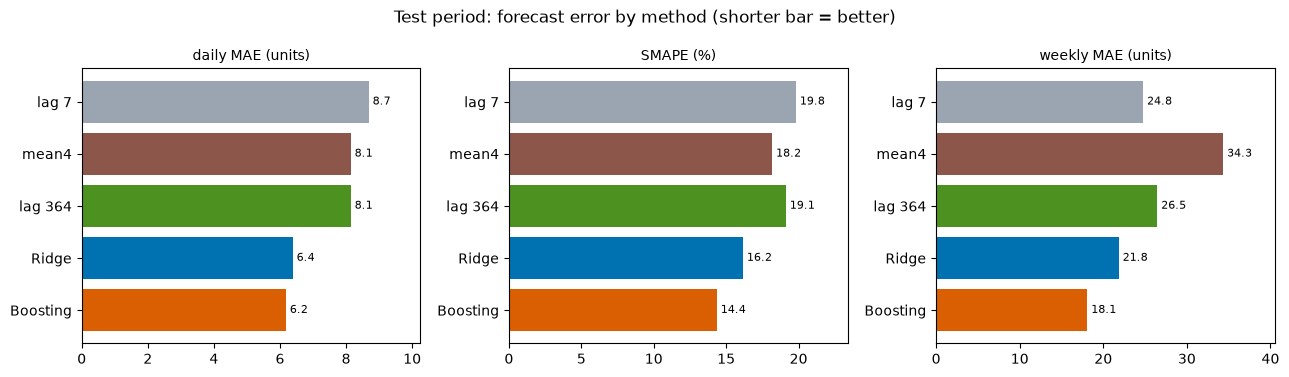

In [32]:
# - README numbers; new files, no frozen file touched
out = test_table.copy()
out.index.name = "method"
out.round(4).to_csv(RESULTS / "test_accuracy_summary.csv")
cmp_table.round(4).to_csv(RESULTS / "test_headline_vs_baseline_accuracy.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, test_table.columns):
    ax.barh([SHORT[m] for m in METHODS][::-1], test_table[col].to_numpy()[::-1],
            color=[colors[m] for m in METHODS][::-1])
    ax.set_title(col, fontsize=10)
    for y, v in enumerate(test_table[col].to_numpy()[::-1]):
        ax.text(v, y, f" {v:.1f}", va="center", fontsize=8)
    ax.set_xlim(0, test_table[col].max() * 1.18)
fig.suptitle("Test period: forecast error by method (shorter bar = better)")
fig.tight_layout()
fig.savefig(FIGURES / "test_accuracy_by_method.png", dpi=150)
plt.show()

### What the test accuracy numbers say
*(From `results/test_metrics.json`.)*

- **Boosting has the lowest error of all five methods on all three measures**: daily MAE 6.18, SMAPE 14.36%, weekly MAE 18.09.
- **Against the baselines fixed in advance**: daily MAE 6.18 against 8.14 for mean4 (-24.1%); SMAPE 14.36 against 18.17 (-21.0%); weekly MAE 18.09 against 26.45 for lag 364 (-31.6%). Ridge also beats them on all three measures, by less: daily MAE -21.6%, SMAPE -11.1%, weekly MAE -17.4%.
- **The two models were close on validation, but not on the test.** On validation Ridge was slightly ahead on daily MAE (6.52 against 6.63). On the test boosting is ahead: 6.18 against 6.38 daily, 14.36% against 16.16% SMAPE, 18.09 against 21.85 weekly. One quarter is a small sample, so I do not claim boosting is better in general.

## 10. Test results: what would the orders have cost?

Now the question the shop owner cares about. For each of the 13 full test weeks and each of the 8 items, every method's weekly forecast becomes an order, using the **buffers fixed on validation** (and, separately, buffer 0), and the order is priced with the assumed costs. Nothing is tuned on the test. Lower cost is better.

In [33]:
print("TEST order cost at the default ratio 3:1 (104 item-weeks; the buffers were frozen on validation):")
display(cost_table(test_costs, HEADLINE_RATIO))
bb = test_costs["best_baseline"]
print("Pre-fixed best baseline at 3:1:", NAMES[bb["3:1"]["tuned_buffer"]], "(tuned buffer);", NAMES[bb["3:1"]["zero_buffer"]], "(buffer 0)")

TEST order cost at the default ratio 3:1 (104 item-weeks; the buffers were frozen on validation):


,buffer,"cost, tuned buffer","cost, buffer 0",units short (tuned),units left over (tuned)
Same day last week (lag 7),0.04,4050,4341,436,2742
Mean of last 4 same weekdays,0.02,4929,5043,514,3387
Same day last year (lag 364),0.08,4188,7257,787,1827
Ridge regression,0.04,3972,5036,750,1722
Gradient boosting,0.04,3100,4403,571,1387


Pre-fixed best baseline at 3:1: Same day last year (lag 364) (tuned buffer); Mean of last 4 same weekdays (buffer 0)


### Sensitivity: the three cost ratios

In [34]:
sens_t = pd.DataFrame(test_costs["sensitivity"])
view_t = sens_t.pivot_table(index="method", columns=["cost_ratio", "setting"], values="total_cost").loc[METHODS]
view_t.index = [NAMES[m] for m in view_t.index]
view_t = view_t[[(r, s) for r in COST_RATIOS for s in ("tuned_buffer", "zero_buffer")]]
print("TEST total order cost for every ratio, tuned (frozen) buffer and buffer 0:")
display(view_t.astype(int))
cheapest = {(r, s): NAMES[min(METHODS, key=lambda m: test_costs["results"][r][s][m]["total_cost"])]
            for r in COST_RATIOS for s in ("tuned_buffer", "zero_buffer")}
for k, v in cheapest.items():
    print(f"Cheapest method at {k[0]}, {k[1].replace('_', ' ')}: {v}")

TEST total order cost for every ratio, tuned (frozen) buffer and buffer 0:


cost_ratio                            1:1                      3:1                      5:1            
setting                      tuned_buffer zero_buffer tuned_buffer zero_buffer tuned_buffer zero_buffer
Same day last week (lag 7)           2484        2575         4050        4341         4818        6107
Mean of last 4 same weekdays         3319        3579         4929        5043         5713        6507
Same day last year (lag 364)         2445        2751         4188        7257         4991       11763
Ridge regression                     2278        2278         3972        5036         5102        7794
Gradient boosting                    1826        1885         3100        4403         3700        6921

Cheapest method at 1:1, tuned buffer: Gradient boosting
Cheapest method at 1:1, zero buffer: Gradient boosting
Cheapest method at 3:1, tuned buffer: Gradient boosting
Cheapest method at 3:1, zero buffer: Same day last week (lag 7)
Cheapest method at 5:1, tuned buffer: Gradient boosting
Cheapest method at 5:1, zero buffer: Same day last week (lag 7)


### Main model against the baseline fixed in advance, with uncertainty
For each setting I print both costs, the difference (negative means the model is cheaper) and the **95% interval** from a bootstrap over the 13 test weeks (the weeks are re-drawn at random 10,000 times; if the interval contains 0, the test cannot tell the two apart).

In [35]:
rows = []
for ratio in COST_RATIOS:
    for setting in ("tuned_buffer", "zero_buffer"):
        for m in (HEAD, OTHER):
            u = test_costs["uncertainty"][ratio][setting][m]
            rows.append({"ratio": ratio, "buffer": setting.replace("_buffer", ""), "model": NAMES[m],
                         "pre-fixed baseline": NAMES[u["baseline"]], "model cost": u["model_total"],
                         "baseline cost": u["baseline_total"], "difference": round(u["total_difference"]),
                         "difference %": round(u["pct_difference"], 1),
                         "95% interval": f"{u['ci95_low']:.0f} to {u['ci95_high']:.0f}",
                         "weeks model cheaper": f"{u['weeks_a_cheaper']} of {u['n_weeks']}",
                         "interval includes 0": bool(u["ci95_low"] <= 0 <= u["ci95_high"])})
cost_cmp = pd.DataFrame(rows)
display(cost_cmp)
print()
for ratio in COST_RATIOS:
    for setting in ("tuned_buffer", "zero_buffer"):
        u = test_costs["uncertainty"][ratio][setting][HEAD]
        word = "is cheaper than" if u["total_difference"] < 0 else "is NOT cheaper than"
        sure = "the interval includes 0, so this gap could be luck" if u["ci95_low"] <= 0 <= u["ci95_high"] else "the interval excludes 0"
        print(f"{ratio}, {setting.replace('_', ' ')}: {NAMES[HEAD]} ({u['model_total']}) {word} {NAMES[u['baseline']]} ({u['baseline_total']}); "
              f"difference {u['total_difference']:+.0f} ({u['pct_difference']:+.1f}%), 95% interval {u['ci95_low']:.0f} to {u['ci95_high']:.0f}; {sure}.")

,ratio,buffer,model,pre-fixed baseline,model cost,baseline cost,difference,difference %,95% interval,weeks model cheaper,interval includes 0
0,1:1,tuned,Gradient boosting,Same day last year (lag 364),1826,2445,-619,-25.3,-878 to -339,12 of 13,False
1,1:1,tuned,Ridge regression,Same day last year (lag 364),2278,2445,-167,-6.8,-516 to 186,8 of 13,True
2,1:1,zero,Gradient boosting,Same day last year (lag 364),1885,2751,-866,-31.5,-1189 to -526,12 of 13,False
3,1:1,zero,Ridge regression,Same day last year (lag 364),2278,2751,-473,-17.2,-970 to 23,10 of 13,True
4,3:1,tuned,Gradient boosting,Same day last year (lag 364),3100,4188,-1088,-26.0,-1565 to -574,11 of 13,False
5,3:1,tuned,Ridge regression,Same day last year (lag 364),3972,4188,-216,-5.2,-1131 to 776,7 of 13,True
6,3:1,zero,Gradient boosting,Mean of last 4 same weekdays,4403,5043,-640,-12.7,-2045 to 565,7 of 13,True
7,3:1,zero,Ridge regression,Mean of last 4 same weekdays,5036,5043,-7,-0.1,-1685 to 1657,7 of 13,True
8,5:1,tuned,Gradient boosting,Same day last year (lag 364),3700,4991,-1291,-25.9,-1982 to -525,10 of 13,False
9,5:1,tuned,Ridge regression,Same day last year (lag 364),5102,4991,111,2.2,-1304 to 1678,8 of 13,True



1:1, tuned buffer: Gradient boosting (1826) is cheaper than Same day last year (lag 364) (2445); difference -619 (-25.3%), 95% interval -878 to -339; the interval excludes 0.
1:1, zero buffer: Gradient boosting (1885) is cheaper than Same day last year (lag 364) (2751); difference -866 (-31.5%), 95% interval -1189 to -526; the interval excludes 0.
3:1, tuned buffer: Gradient boosting (3100) is cheaper than Same day last year (lag 364) (4188); difference -1088 (-26.0%), 95% interval -1565 to -574; the interval excludes 0.
3:1, zero buffer: Gradient boosting (4403) is cheaper than Mean of last 4 same weekdays (5043); difference -640 (-12.7%), 95% interval -2045 to 565; the interval includes 0, so this gap could be luck.
5:1, tuned buffer: Gradient boosting (3700) is cheaper than Same day last year (lag 364) (4991); difference -1291 (-25.9%), 95% interval -1982 to -525; the interval excludes 0.
5:1, zero buffer: Gradient boosting (6921) is NOT cheaper than Mean of last 4 same weekdays (6

**Boosting against Ridge.** The cost difference between the two models at each ratio and buffer setting, with a 95% interval and the number of weeks boosting was cheaper. It shows whether the cost gain belongs to boosting in particular.

In [36]:
print("Headline model against the other model (boosting minus Ridge, negative = boosting cheaper):")
rows = []
for ratio in COST_RATIOS:
    for setting in ("tuned_buffer", "zero_buffer"):
        u = test_costs["headline_vs_other_model"][ratio][setting]
        rows.append({"ratio": ratio, "buffer": setting.replace("_buffer", ""), "difference": round(u["total_difference"]),
                     "95% interval": f"{u['ci95_low']:.0f} to {u['ci95_high']:.0f}",
                     "weeks boosting cheaper": f"{u['weeks_a_cheaper']} of {u['n_weeks']}"})
display(pd.DataFrame(rows))

Headline model against the other model (boosting minus Ridge, negative = boosting cheaper):


,ratio,buffer,difference,95% interval,weeks boosting cheaper
0,1:1,tuned,-452,-743 to -192,9 of 13
1,1:1,zero,-393,-712 to -104,8 of 13
2,3:1,tuned,-872,-1650 to -198,11 of 13
3,3:1,zero,-633,-1563 to 107,7 of 13
4,5:1,tuned,-1402,-2601 to -347,10 of 13
5,5:1,zero,-873,-2470 to 381,5 of 13


### Per item, and where a simple rule wins
The overall total can hide that the best method differs by item. Below: cost per item at 3 : 1 with the buffers fixed on validation, the cheapest method per item, and the list of items where some simple rule was cheaper than the model.

In [37]:
per_item_t = pd.DataFrame({m: test_costs["results"][HEADLINE_RATIO]["tuned_buffer"][m]["cost_per_item"] for m in METHODS})
per_item_t.columns = [SHORT[m] for m in METHODS]
per_item_t.index.name = "item"
per_item_t["cheapest"] = per_item_t.idxmin(axis=1)
print("TEST cost per item at 3:1, frozen tuned buffers:")
display(per_item_t)
for model in (HEAD, OTHER):
    wins = test_costs["simple_rule_wins_by_model"][model]
    print(f"\nItems where a simple rule was cheaper than {NAMES[model]} (frozen tuned buffers):")
    for ratio in COST_RATIOS:
        entries = wins[ratio]
        text = "; ".join(f"item {e['item']} (model {e['model_cost']}, " + ", ".join(f"{SHORT[b]} {c}" for b, c in e["cheaper_baselines"].items()) + ")" for e in entries)
        print(f"  {ratio}: {len(entries)} of 8 items" + (f": {text}" if entries else ""))

TEST cost per item at 3:1, frozen tuned buffers:


,lag 7,mean4,lag 364,Ridge,Boosting,cheapest
item,,,,,,
5,313,244,268,547,169,Boosting
15,508,952,715,526,448,Boosting
16,253,366,259,475,204,Boosting
20,506,537,552,567,454,Boosting
25,718,909,540,547,546,lag 364
31,520,707,577,431,444,Ridge
33,717,655,735,486,470,Boosting
42,515,559,542,393,365,Boosting



Items where a simple rule was cheaper than Gradient boosting (frozen tuned buffers):
  1:1: 1 of 8 items: item 25 (model 333, lag 364 293)
  3:1: 1 of 8 items: item 25 (model 546, lag 364 540)
  5:1: 1 of 8 items: item 25 (model 718, lag 364 579)

Items where a simple rule was cheaper than Ridge regression (frozen tuned buffers):
  1:1: 4 of 8 items: item 5 (model 225, lag 7 205, mean4 167, lag 364 157); item 15 (model 356, lag 7 326); item 16 (model 235, lag 7 174, mean4 230, lag 364 162); item 25 (model 384, lag 364 293)
  3:1: 5 of 8 items: item 5 (model 547, lag 7 313, mean4 244, lag 364 268); item 15 (model 526, lag 7 508); item 16 (model 475, lag 7 253, mean4 366, lag 364 259); item 20 (model 567, lag 7 506, mean4 537, lag 364 552); item 25 (model 547, lag 364 540)
  5:1: 5 of 8 items: item 5 (model 815, lag 7 396, mean4 296, lag 364 335); item 15 (model 609, lag 7 563); item 16 (model 678, lag 7 295, mean4 416, lag 364 309); item 20 (model 727, lag 7 614, mean4 597, lag 364 637

**Test cost picture.** Left: total order cost per cost ratio for each method. Right: the weekly cost of boosting against the baseline fixed in advance, week by week. Also saves the cost tables as new files in `results/`.

PASS  104 test item-weeks (13 weeks x 8 items)


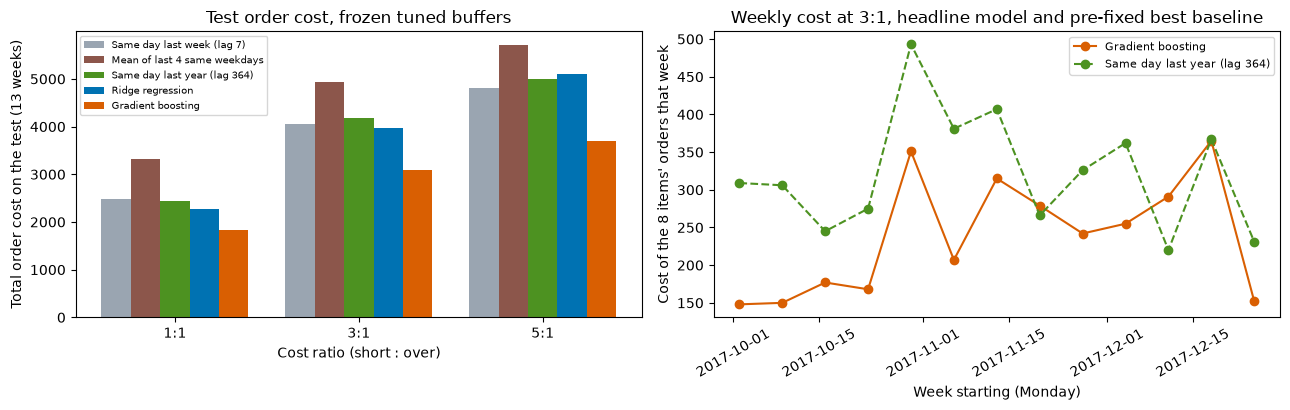

In [38]:
from simulate import simulate_method
frozen_buffers = load_buffers()["buffers"]                 # - read only
test_weekly = weekly_table(test_pred, TEST_WEEK_MONDAYS)
check("104 test item-weeks (13 weeks x 8 items)", len(test_weekly) == 104)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
width = 0.16
for k, m in enumerate(METHODS):
    vals = [test_costs["results"][r]["tuned_buffer"][m]["total_cost"] for r in COST_RATIOS]
    axes[0].bar(np.arange(3) + (k - 2) * width, vals, width, label=NAMES[m], color=colors[m])
axes[0].set_xticks(np.arange(3), [f"{r}" for r in COST_RATIOS])
axes[0].set_xlabel("Cost ratio (short : over)")
axes[0].set_ylabel("Total order cost on the test (13 weeks)")
axes[0].set_title("Test order cost, frozen tuned buffers")
axes[0].legend(fontsize=7, loc="upper left")

best_b = test_costs["best_baseline"][HEADLINE_RATIO]["tuned_buffer"]
for m, ls in ((HEAD, "-"), (best_b, "--")):
    sim = simulate_method(test_weekly, m, frozen_buffers[HEADLINE_RATIO][m], C_SHORT, C_OVER)
    weekly_cost = sim.groupby("week_monday")["cost"].sum()
    axes[1].plot(weekly_cost.index, weekly_cost.values, ls, marker="o", color=colors[m], label=NAMES[m])
axes[1].set_title("Weekly cost at 3:1, headline model and pre-fixed best baseline")
axes[1].set_xlabel("Week starting (Monday)")
axes[1].set_ylabel("Cost of the 8 items' orders that week")
axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIGURES / "test_order_cost.png", dpi=150)
plt.show()

view_t.astype(int).to_csv(RESULTS / "test_order_cost_summary.csv")
cost_cmp.to_csv(RESULTS / "test_headline_vs_baseline_cost.csv", index=False)

### What the test order costs say, including where a simple rule wins
*(From `results/simulation_test.json`.)*

**Main result (buffers fixed on validation).** Boosting is cheaper than the baseline fixed in advance (lag 364) at all three cost ratios:
- **3 : 1:** 3100 against 4188, a difference of -1088 (-26.0%), 95% interval -1565 to -574, boosting cheaper in 11 of 13 weeks.
- **1 : 1:** 1826 against 2445 (-25.3%), interval -878 to -339.
- **5 : 1:** 3700 against 4991 (-25.9%), interval -1982 to -525.

Lag 7 turned out to be the cheapest simple rule on the test, but it was not the baseline fixed in advance. Boosting is 23.5% cheaper than lag 7 at 3 : 1 (3100 against 4050); I did not compute an interval for that.

**Where a simple rule wins or the result is weaker:**
- **With no buffer, a simple rule can win.** At 3 : 1 same day last week costs 4341 against 4403 for boosting. At 5 : 1 same day last week (6107) and mean4 (6507) both beat boosting (6921).
- **Ridge does not clearly beat the simple rules on cost.** At 3 : 1 it is -5.2% against lag 364 (interval -1131 to 776, includes 0).
- **Item 25:** lag 364 (540) beat boosting (546) at 3 : 1, by a small margin.
- **Limits:** 3 : 1 is my guess, the buffers were tuned on validation, and 13 weeks is a small sample.

## 11. Failure analysis on the test: where and why is the model wrong?

A forecast score tells how much error there is. The failure analysis asks where the error sits and why. I use the same function (`src/failure_analysis.py`) that was written and tested on validation, now called on the test forecasts that the guarded run returned. The rules (what counts as a bad day, which example is drawn, which tests are run) were fixed before the test.

**Sign convention:** error = forecast minus actual. Positive means the forecast was too high; negative means too low.

**Noise.** Sales are partly luck, so even a perfect forecast would miss. If a day averages 50 sales, normal luck is about plus or minus 7 (the square root of 50). The analysis measures many misses in **noise units**: the miss divided by the square root of the forecast. About 1 is ordinary luck, 3 or more is surprising. The **noise floor** is my estimate of how big the average miss would be even with a perfect forecast. Ideas I have not tested are labelled as hypotheses.

In [39]:
from run_failure_test import run_failure_test
%matplotlib inline
failure = run_failure_test(final)          # - writes failure_test_* files
fs = failure
print("Headline model:", fs["headline_model"], " period:", fs["period_label"], fs["date_range"])
print("Rows:", fs["n_daily_rows"], " item-weeks:", fs["n_item_weeks"], " sign:", fs["sign_convention"])
written = sorted(p.name for p in RESULTS.glob("failure_test_*")) + sorted(p.name for p in FIGURES.glob("failure_test_*"))
print(len(written), "files written:", written)

Headline model: hgb  period: test ['2017-10-01', '2017-12-31']
Rows: 736  item-weeks: 104  sign: error = forecast minus actual; positive = over-forecast
13 files written: ['failure_test_by_item.csv', 'failure_test_by_item_month.csv', 'failure_test_by_month.csv', 'failure_test_by_weekday.csv', 'failure_test_summary.json', 'failure_test_worst_days.csv', 'failure_test_bias.png', 'failure_test_by_item.png', 'failure_test_ceiling.png', 'failure_test_example.png', 'failure_test_example_ridge.png', 'failure_test_noise.png', 'failure_test_rule_beats_ridge.png']


### The 10 worst days (main model)
Each row is one item on one day. The last three columns show what the simple rules forecast for the same day. If all three were also too high, or all too low, the surprise was in the sales, not specific to the model.

In [40]:
worst = pd.read_csv(RESULTS / "failure_test_worst_days.csv")
w = worst[worst["model"] == HEAD].sort_values("rank")
display(w.drop(columns=["model", "abs_error"]).rename(columns={
    "baseline_lag7": "lag 7", "baseline_mean4": "mean4", "baseline_lag364": "lag 364"}).reset_index(drop=True))
rel = fs["error_relationships"]
print(f"Of the 10 worst days, {rel['worst10_days_all_baselines_also_wrong_same_direction'][HEAD]} were also missed in the same direction by all three simple rules.")
print(f"Overlap: {rel['worst10_days_shared_by_first_two_models']} of the worst 10 days are the same for Ridge and boosting.")
w_other = worst[worst["model"] == OTHER].sort_values("rank")
print("\nFor comparison, the 10 worst days of Ridge (date, item, error):")
print([(r.date, int(r.item), r.error) for r in w_other.itertuples()])

,rank,date,weekday,item,actual,predicted,error,noise_units,lag 7,mean4,lag 364
0,1,2017-12-15,Friday,15,51.0,79.88,28.88,3.23,79.0,89.00,83.0
1,2,2017-11-04,Saturday,25,118.0,93.17,-24.83,-2.57,95.0,87.25,94.0
2,3,2017-11-03,Friday,25,108.0,83.92,-24.08,-2.63,89.0,80.25,85.0
3,4,2017-11-12,Sunday,15,133.0,109.00,-24.00,-2.30,110.0,96.75,108.0
4,5,2017-12-09,Saturday,15,89.0,65.26,-23.74,-2.94,77.0,95.50,67.0
5,6,2017-11-11,Saturday,31,92.0,68.92,-23.08,-2.78,76.0,73.50,53.0
6,7,2017-11-01,Wednesday,33,82.0,59.47,-22.53,-2.92,64.0,60.50,50.0
7,8,2017-10-13,Friday,20,67.0,44.97,-22.03,-3.28,44.0,45.00,42.0
8,9,2017-10-14,Saturday,25,66.0,87.67,21.67,2.31,93.0,91.75,77.0
9,10,2017-11-20,Monday,33,42.0,63.41,21.41,2.69,52.0,55.50,63.0


Of the 10 worst days, 9 were also missed in the same direction by all three simple rules.
Overlap: 6 of the worst 10 days are the same for Ridge and boosting.

For comparison, the 10 worst days of Ridge (date, item, error):
[('2017-11-12', 15, -30.55), ('2017-12-15', 15, 30.07), ('2017-11-04', 25, -27.12), ('2017-11-11', 31, -23.21), ('2017-11-03', 25, -23.13), ('2017-10-13', 20, -21.87), ('2017-10-19', 31, -21.83), ('2017-11-05', 25, -21.1), ('2017-12-01', 15, 21.02), ('2017-11-04', 33, -20.55)]


### Error by item volume, by weekday and by month
Small items are relatively noisier (percent error); big items have bigger errors in units. Bias is the average signed error: a negative number means the method tends to forecast too low.

In [41]:
by_item = pd.read_csv(RESULTS / "failure_test_by_item.csv")
cols = ["item", "mean_sales"] + [f"{m}_mae" for m in METHODS]
t = by_item[cols].copy()
t.columns = ["item", "mean sales/day (test)"] + [SHORT[m] + " MAE" for m in METHODS]
t["best method (daily MAE)"] = by_item["best_method_daily_mae"].map(SHORT)
print("Daily MAE per item, items from the smallest to the largest seller:")
display(t.round(2))
rel_cols = ["item", "mean_sales", f"{HEAD}_mae_rel_pct", f"{OTHER}_mae_rel_pct", f"{HEAD}_bias", f"{OTHER}_bias", f"{HEAD}_weekly_bias", f"{OTHER}_weekly_bias"]
r = by_item[rel_cols].copy()
r.columns = ["item", "mean sales/day", "boosting MAE % of sales", "Ridge MAE % of sales", "boosting bias (units/day)", "Ridge bias (units/day)",
             "boosting weekly bias", "Ridge weekly bias"]
display(r.round(2))

Daily MAE per item, items from the smallest to the largest seller:


,item,mean sales/day (test),lag 7 MAE,mean4 MAE,lag 364 MAE,Ridge MAE,Boosting MAE,best method (daily MAE)
0,5,17.13,4.63,4.17,4.49,4.27,3.32,Boosting
1,16,23.93,6.82,5.91,6.40,5.39,4.98,Boosting
2,42,34.12,6.92,7.21,6.71,4.93,5.10,Ridge
3,20,45.46,8.88,7.41,7.61,6.02,5.78,Boosting
4,31,56.40,9.34,8.77,8.42,6.67,6.56,Boosting
5,33,66.01,10.25,9.48,9.76,7.36,7.34,Boosting
6,25,76.57,11.63,10.83,10.40,8.40,8.17,Boosting
7,15,84.23,11.00,11.34,11.33,8.04,8.17,Ridge


,item,mean sales/day,boosting MAE % of sales,Ridge MAE % of sales,boosting bias (units/day),Ridge bias (units/day),boosting weekly bias,Ridge weekly bias
0,5,17.13,19.40,24.93,0.16,-1.83,0.84,-13.25
1,16,23.93,20.80,22.51,-0.40,-1.67,-3.48,-12.55
2,42,34.12,14.95,14.44,0.67,-0.42,4.84,-2.92
3,20,45.46,12.71,13.23,-1.53,-1.59,-11.53,-11.94
4,31,56.40,11.63,11.83,-0.69,-0.44,-5.20,-3.42
5,33,66.01,11.12,11.15,-1.83,-0.34,-12.92,-2.55
6,25,76.57,10.67,10.97,-0.97,0.69,-6.39,5.39
7,15,84.23,9.70,9.54,-2.02,0.62,-14.44,4.35


**Error by weekday and by month.** Average miss and bias for each weekday and each month of the test, for Ridge, boosting and mean4. Months matter here because the test quarter ends in the steep fall into December.

In [42]:
by_wd = pd.read_csv(RESULTS / "failure_test_by_weekday.csv")
by_mo = pd.read_csv(RESULTS / "failure_test_by_month.csv")
keep = ["n_rows", "mean_sales", "ridge_mae", "ridge_bias", "hgb_mae", "hgb_bias", "baseline_mean4_mae", "baseline_mean4_bias"]
names = {"n_rows": "days", "mean_sales": "mean sales", "ridge_mae": "Ridge MAE", "ridge_bias": "Ridge bias", "hgb_mae": "boosting MAE",
         "hgb_bias": "boosting bias", "baseline_mean4_mae": "mean4 MAE", "baseline_mean4_bias": "mean4 bias"}
print("By weekday (test; bias = average of forecast minus actual, units per day):")
display(by_wd.set_index("weekday")[keep].rename(columns=names).round(2))
print("By month (test):")
display(by_mo.set_index("month")[keep].rename(columns=names).round(2))

By weekday (test; bias = average of forecast minus actual, units per day):


,days,mean sales,Ridge MAE,Ridge bias,boosting MAE,boosting bias,mean4 MAE,mean4 bias
weekday,,,,,,,,
1 Monday,104,40.38,6.70,-0.93,5.97,-0.62,6.92,2.28
2 Tuesday,104,47.07,5.64,-0.82,5.16,-1.12,7.26,2.44
3 Wednesday,104,47.89,6.02,-0.86,5.98,-1.10,7.77,2.61
4 Thursday,104,50.64,6.43,-0.74,6.75,-0.59,7.93,3.01
5 Friday,104,51.82,6.86,-0.11,6.58,-0.27,9.78,3.48
6 Saturday,104,56.12,6.91,-0.89,6.69,-1.22,8.36,3.18
7 Sunday,112,58.79,6.15,-0.06,6.12,-0.88,8.89,3.39


By month (test):


,days,mean sales,Ridge MAE,Ridge bias,boosting MAE,boosting bias,mean4 MAE,mean4 bias
month,,,,,,,,
2017-10,248,53.11,6.10,-1.10,5.91,-0.99,6.80,1.76
2017-11,240,57.22,6.52,-0.90,6.52,-1.41,7.16,-2.08
2017-12,248,41.33,6.53,0.12,6.11,-0.09,10.42,8.92


### Is the error more than counting noise? (numbers read from the summary)
For each model: the average miss against the noise floor, how large the biggest misses are compared with what pure luck would produce
(simulated 2,000 times in the analysis), and how many days were off by more than 3 noise units.

In [43]:
rows = []
for m in METHODS:
    o = fs["overall"][m]
    rows.append({"method": NAMES[m], "daily MAE": o["mae"], "noise floor MAE": o["noise_floor_mae"],
                 "bias (units/day)": o["bias"], "weekly MAE": o["weekly_mae"], "weekly noise floor": o["noise_floor_weekly_mae"],
                 "weekly bias": o["weekly_bias"], "error variance / noise variance": o["error_variance_vs_noise"]})
display(pd.DataFrame(rows).set_index("method").round(2))
print("(error variance / noise variance of 1.0 would mean all remaining error is counting noise)\n")
for m in (HEAD, OTHER):
    nc = fs["noise_check"][m]
    print(f"{NAMES[m]}: biggest daily miss {nc['max_abs_error']:.1f} units; with pure noise the biggest miss of {fs['n_daily_rows']} days "
          f"would average {nc['noise_only_max_abs_error_mean']:.1f} (95% of simulations below {nc['noise_only_max_abs_error_p95']:.1f}).")
    print(f"    10th biggest miss {nc['tenth_largest_abs_error']:.1f} against {nc['noise_only_tenth_largest_mean']:.1f} expected from noise "
          f"(95% below {nc['noise_only_tenth_largest_p95']:.1f}).")
    print(f"    Days off by more than 3 noise units: {nc['days_noise_units_over_3']} (expected from pure noise: "
          f"{nc['days_noise_units_over_3_expected_pure_noise']:.1f}). Spread of the errors in noise units: {nc['noise_units_std']:.2f} (1.00 = pure noise).")
    tail = "larger than" if nc["max_abs_error"] > nc["noise_only_max_abs_error_p95"] else "within the range of"
    print(f"    So the single biggest miss is {tail} what noise alone would produce; the share of the 10 worst days where the forecast was too high: {100*nc['top10_share_over_forecast']:.0f}%.")

,daily MAE,noise floor MAE,bias (units/day),weekly MAE,weekly noise floor,weekly bias,error variance / noise variance
method,,,,,,,
Same day last week (lag 7),8.68,5.52,1.22,24.76,14.67,7.78,2.60
Mean of last 4 same weekdays,8.14,5.64,2.92,34.33,14.94,20.14,1.98
Same day last year (lag 364),8.14,5.33,-2.40,26.45,14.17,-16.88,2.49
Ridge regression,6.38,5.42,-0.62,21.84,14.35,-4.61,1.65
Gradient boosting,6.18,5.44,-0.83,18.09,14.40,-6.03,1.29


(error variance / noise variance of 1.0 would mean all remaining error is counting noise)

Gradient boosting: biggest daily miss 28.9 units; with pure noise the biggest miss of 736 days would average 27.7 (95% of simulations below 34.5).
    10th biggest miss 21.4 against 19.1 expected from noise (95% below 20.9).
    Days off by more than 3 noise units: 6 (expected from pure noise: 2.2). Spread of the errors in noise units: 1.13 (1.00 = pure noise).
    So the single biggest miss is within the range of what noise alone would produce; the share of the 10 worst days where the forecast was too high: 30%.
Ridge regression: biggest daily miss 30.6 units; with pure noise the biggest miss of 736 days would average 27.7 (95% of simulations below 34.4).
    10th biggest miss 20.6 against 19.2 expected from noise (95% below 21.0).
    Days off by more than 3 noise units: 18 (expected from pure noise: 2.2). Spread of the errors in noise units: 1.27 (1.00 = pure noise).
    So the single biggest 

### Do the worst days bunch up on a particular weekday, item or month?
I count where the 10 worst days of each model fall and compare that with an even spread. A small p-value (below 0.05) means the bunching is probably not chance. With many such tests, a few small p-values are expected by luck. The table repeats the count in noise units, which removes the effect that large items and busy months simply have bigger errors.

In [44]:
rows = []
for m in (HEAD, OTHER):
    nc = fs["noise_check"][m]
    for label, key in (("10 worst days, raw error", "pattern_top10_by_abs_error"),
                       ("top 5% days, raw error", "pattern_top5pct_by_abs_error"),
                       ("top 5% days, noise units", "pattern_top5pct_by_noise_units")):
        for dim in ("weekday", "item", "month"):
            p = nc[key][dim]
            top = max(zip(p["observed"], p["labels"]), key=lambda x: x[0])
            rows.append({"model": NAMES[m], "test": label, "grouped by": dim, "most common": f"{top[1]} ({top[0]} days, {p['expected'][p['labels'].index(top[1])]:.1f} expected)",
                         "p-value": p["p_value"]})
pat = pd.DataFrame(rows)
display(pat)
small = pat[pat["p-value"] < 0.05]
print("Tests with p-value below 0.05:", len(small), "of", len(pat))

,model,test,grouped by,most common,p-value
0,Gradient boosting,"10 worst days, raw error",weekday,"Saturday (4 days, 1.4 expected)",0.1266
1,Gradient boosting,"10 worst days, raw error",item,"15 (3 days, 1.2 expected)",0.2983
2,Gradient boosting,"10 worst days, raw error",month,"2017-11 (6 days, 3.3 expected)",0.1988
3,Gradient boosting,"top 5% days, raw error",weekday,"Thursday (7 days, 5.2 expected)",0.7119
4,Gradient boosting,"top 5% days, raw error",item,"25 (13 days, 4.6 expected)",0.0002
5,Gradient boosting,"top 5% days, raw error",month,"2017-11 (15 days, 12.1 expected)",0.2701
6,Gradient boosting,"top 5% days, noise units",weekday,"Saturday (9 days, 5.2 expected)",0.2018
7,Gradient boosting,"top 5% days, noise units",item,"16 (7 days, 4.6 expected)",0.7443
8,Gradient boosting,"top 5% days, noise units",month,"2017-12 (15 days, 12.5 expected)",0.6741
9,Ridge regression,"10 worst days, raw error",weekday,"Friday (4 days, 1.4 expected)",0.0890


Tests with p-value below 0.05: 4 of 18


### Pictures of the failures
**Predicted against actual for a wrong forecast.** The next figure is picked by a rule fixed in advance (the item-week where the main model's weekly total is furthest from the truth), not by hand.

Example chosen by the fixed rule: item 25, week starting 2017-12-11: forecast 411.4 units, actual 475.0, error -63.6 units (-13.4%). The simple rules forecast {'baseline_lag7': 448.0, 'baseline_mean4': 531.5, 'baseline_lag364': 428.0}
Headline model: predicted against actual around the worst item-week


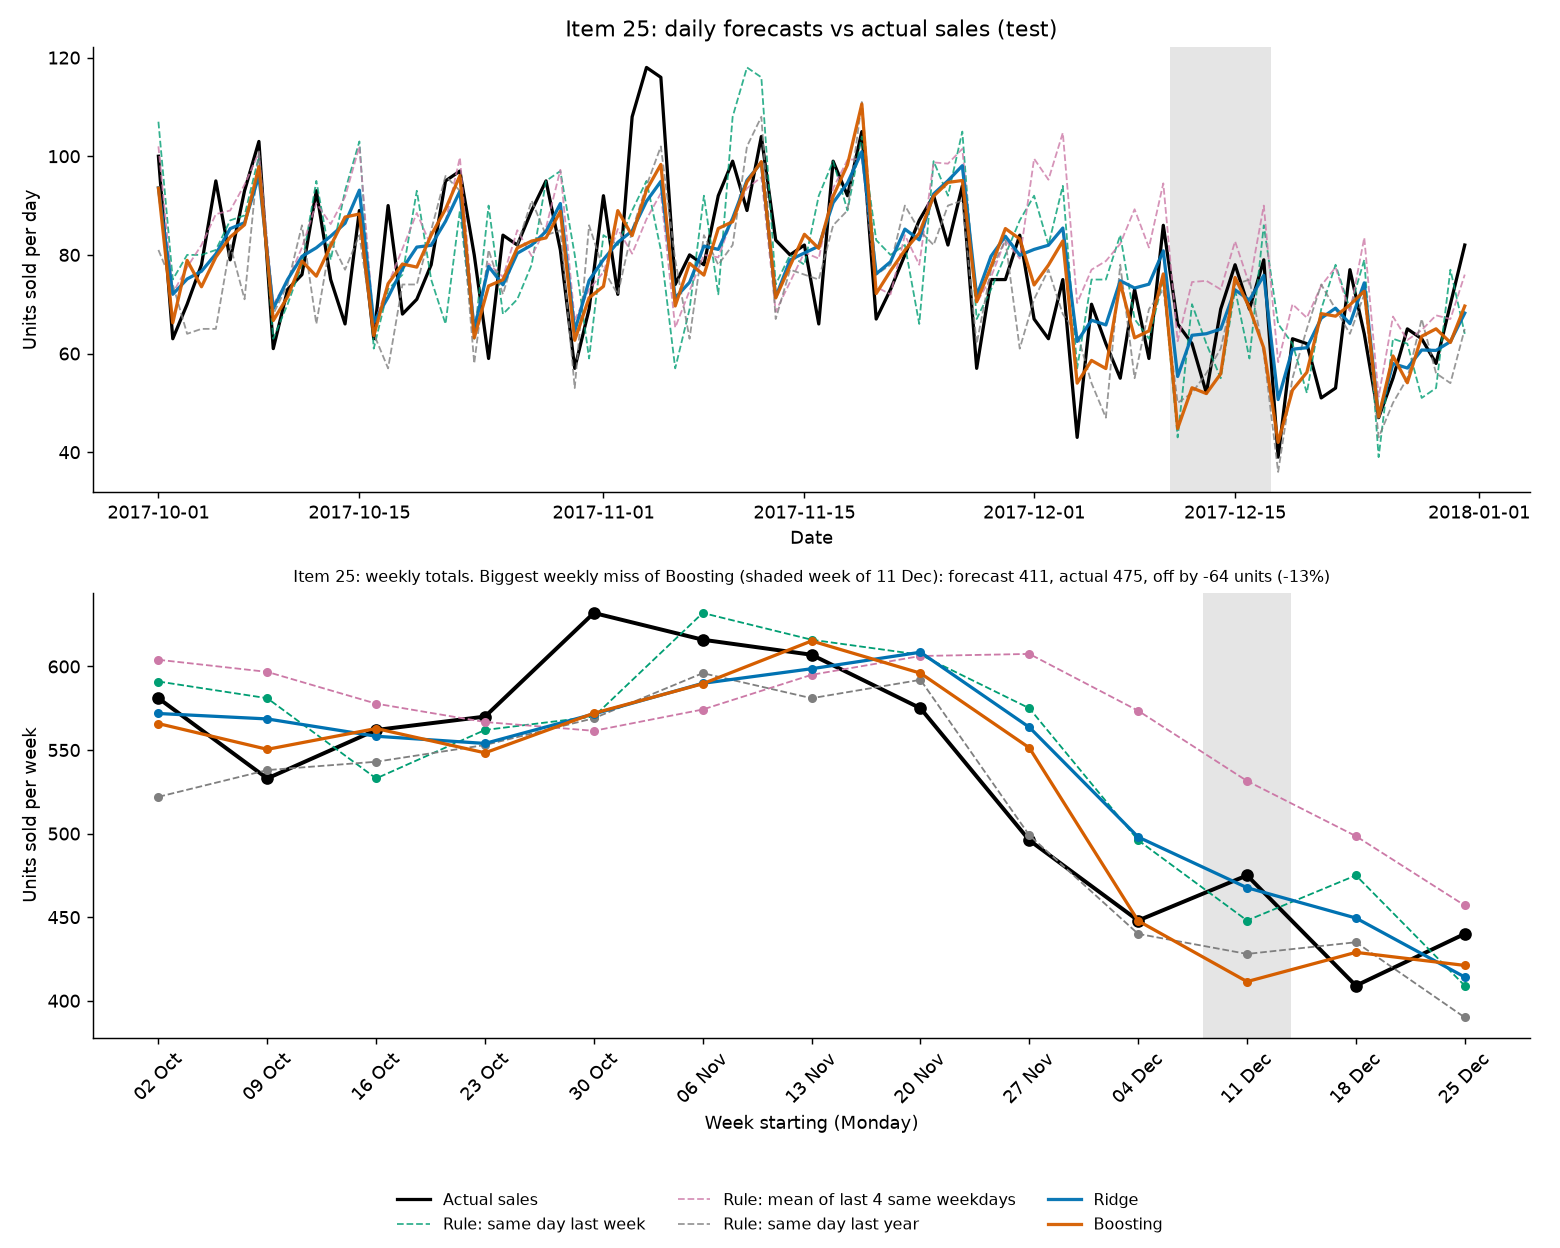

In [45]:
def show_fig(name, caption, width=900):
    path = FIGURES / name
    if path.exists():
        print(caption)
        display(Image(filename=str(path), width=width))
    else:
        print(f"({name} was not drawn: {caption})")

ex = fs["example_figure"]
print(f"Example chosen by the fixed rule: item {ex['item']}, week starting {ex['week_monday']}: forecast {ex['weekly_forecast']:.1f} units, "
      f"actual {ex['weekly_actual']:.1f}, error {ex['weekly_error']:+.1f} units ({ex['weekly_error_pct']:+.1f}%). "
      f"The simple rules forecast {ex['baseline_weekly_forecasts']}")
show_fig("failure_test_example.png", "Headline model: predicted against actual around the worst item-week")

**My own plot of the item with boosting's worst day**, over the whole test period, with the other worst days of that item in red.

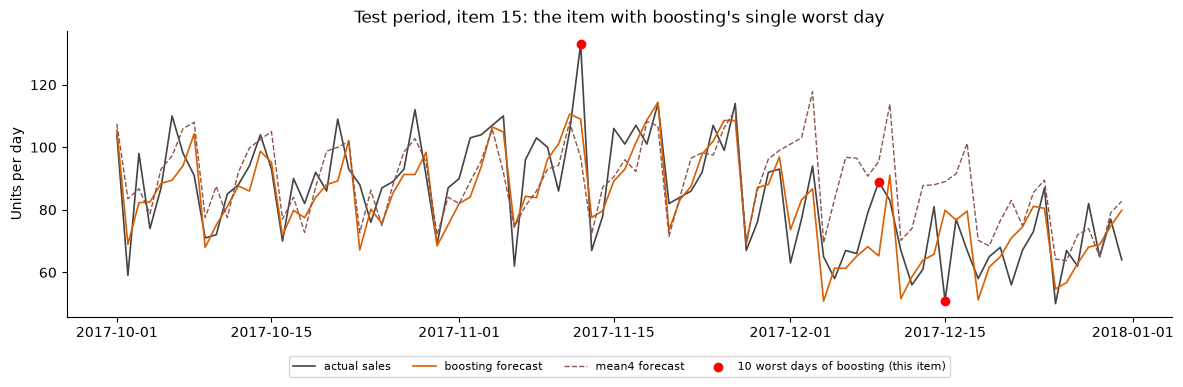

In [46]:
# - item with the headline model's worst day, whole test period
top = w.iloc[0]
item = int(top["item"])
d = test_pred[test_pred["item"] == item].sort_values("date")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(d["date"], d["actual"], color="#444444", lw=1.2, label="actual sales")
ax.plot(d["date"], d[HEAD], color=colors[HEAD], lw=1.2, label="boosting forecast")
ax.plot(d["date"], d["baseline_mean4"], color=colors["baseline_mean4"], lw=1, ls="--", label="mean4 forecast")
bad = w[w["item"] == item]
ax.scatter(pd.to_datetime(bad["date"]), bad["actual"], color="red", zorder=5, label="10 worst days of boosting (this item)")
ax.set_title(f"Test period, item {item}: the item with boosting's single worst day")
ax.set_ylabel("Units per day")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
fig.savefig(FIGURES / "test_worst_item_daily.png", dpi=150)
plt.show()

**More failure figures** (error by item, errors against counting noise, bias, ceiling check). The "rule beats boosting" figure is not drawn because no simple rule beat boosting on weekly MAE for any item on the test (see the table below).

(failure_test_rule_beats_hgb.png was not drawn: An item where the best simple rule beats boosting (weekly totals))
Error by item


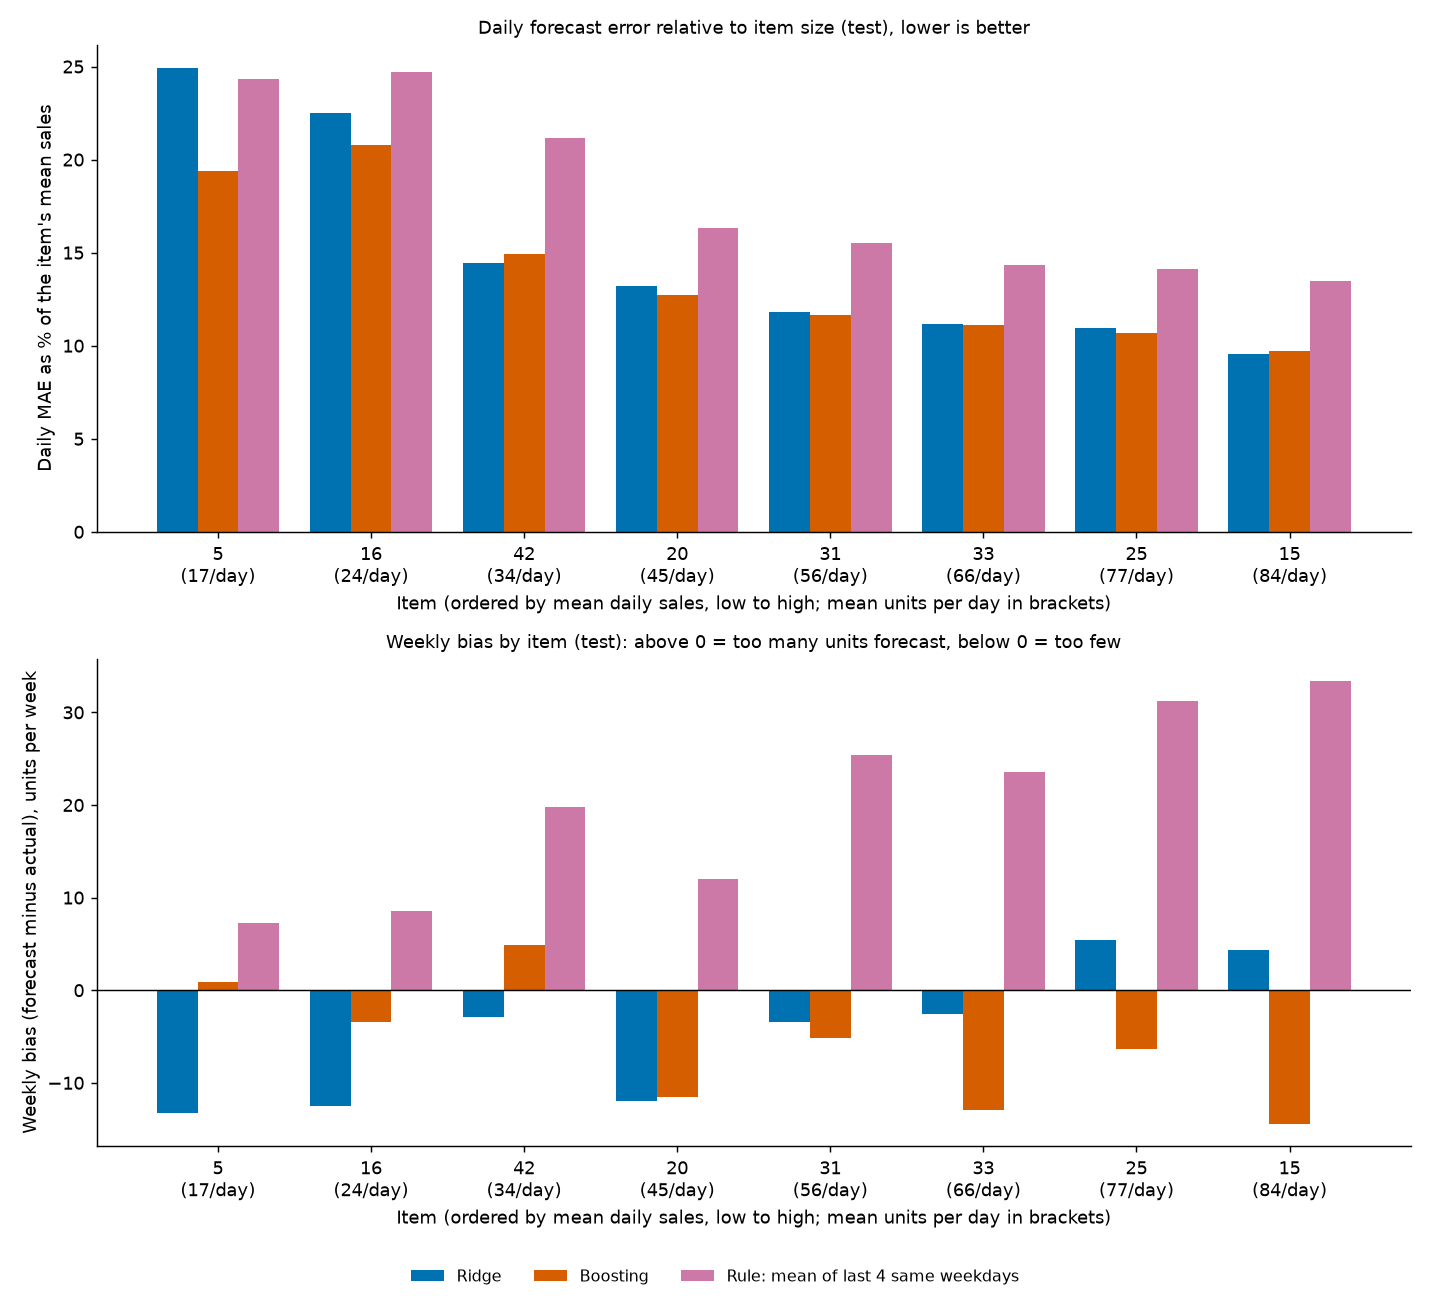

Errors compared with pure counting noise


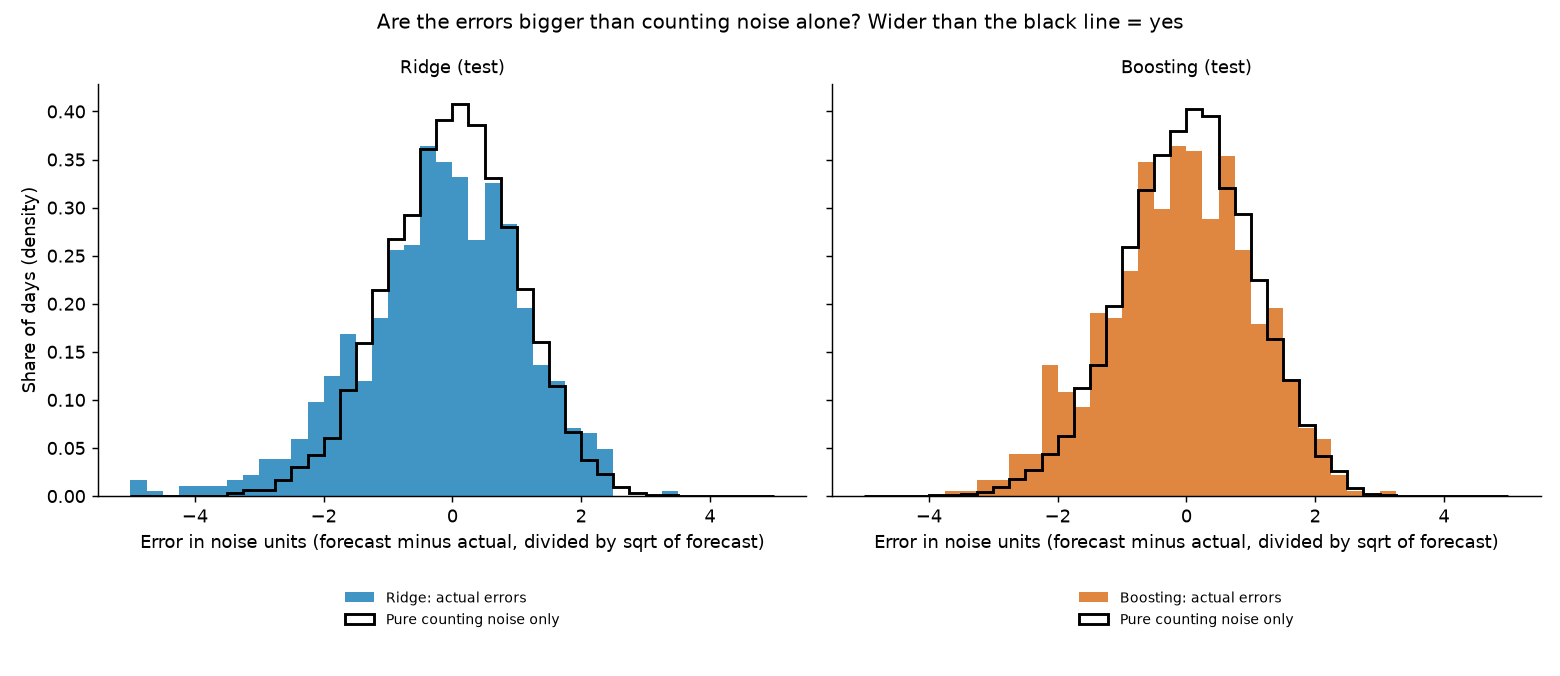

Bias by month and weekday, and how it scales with item volume


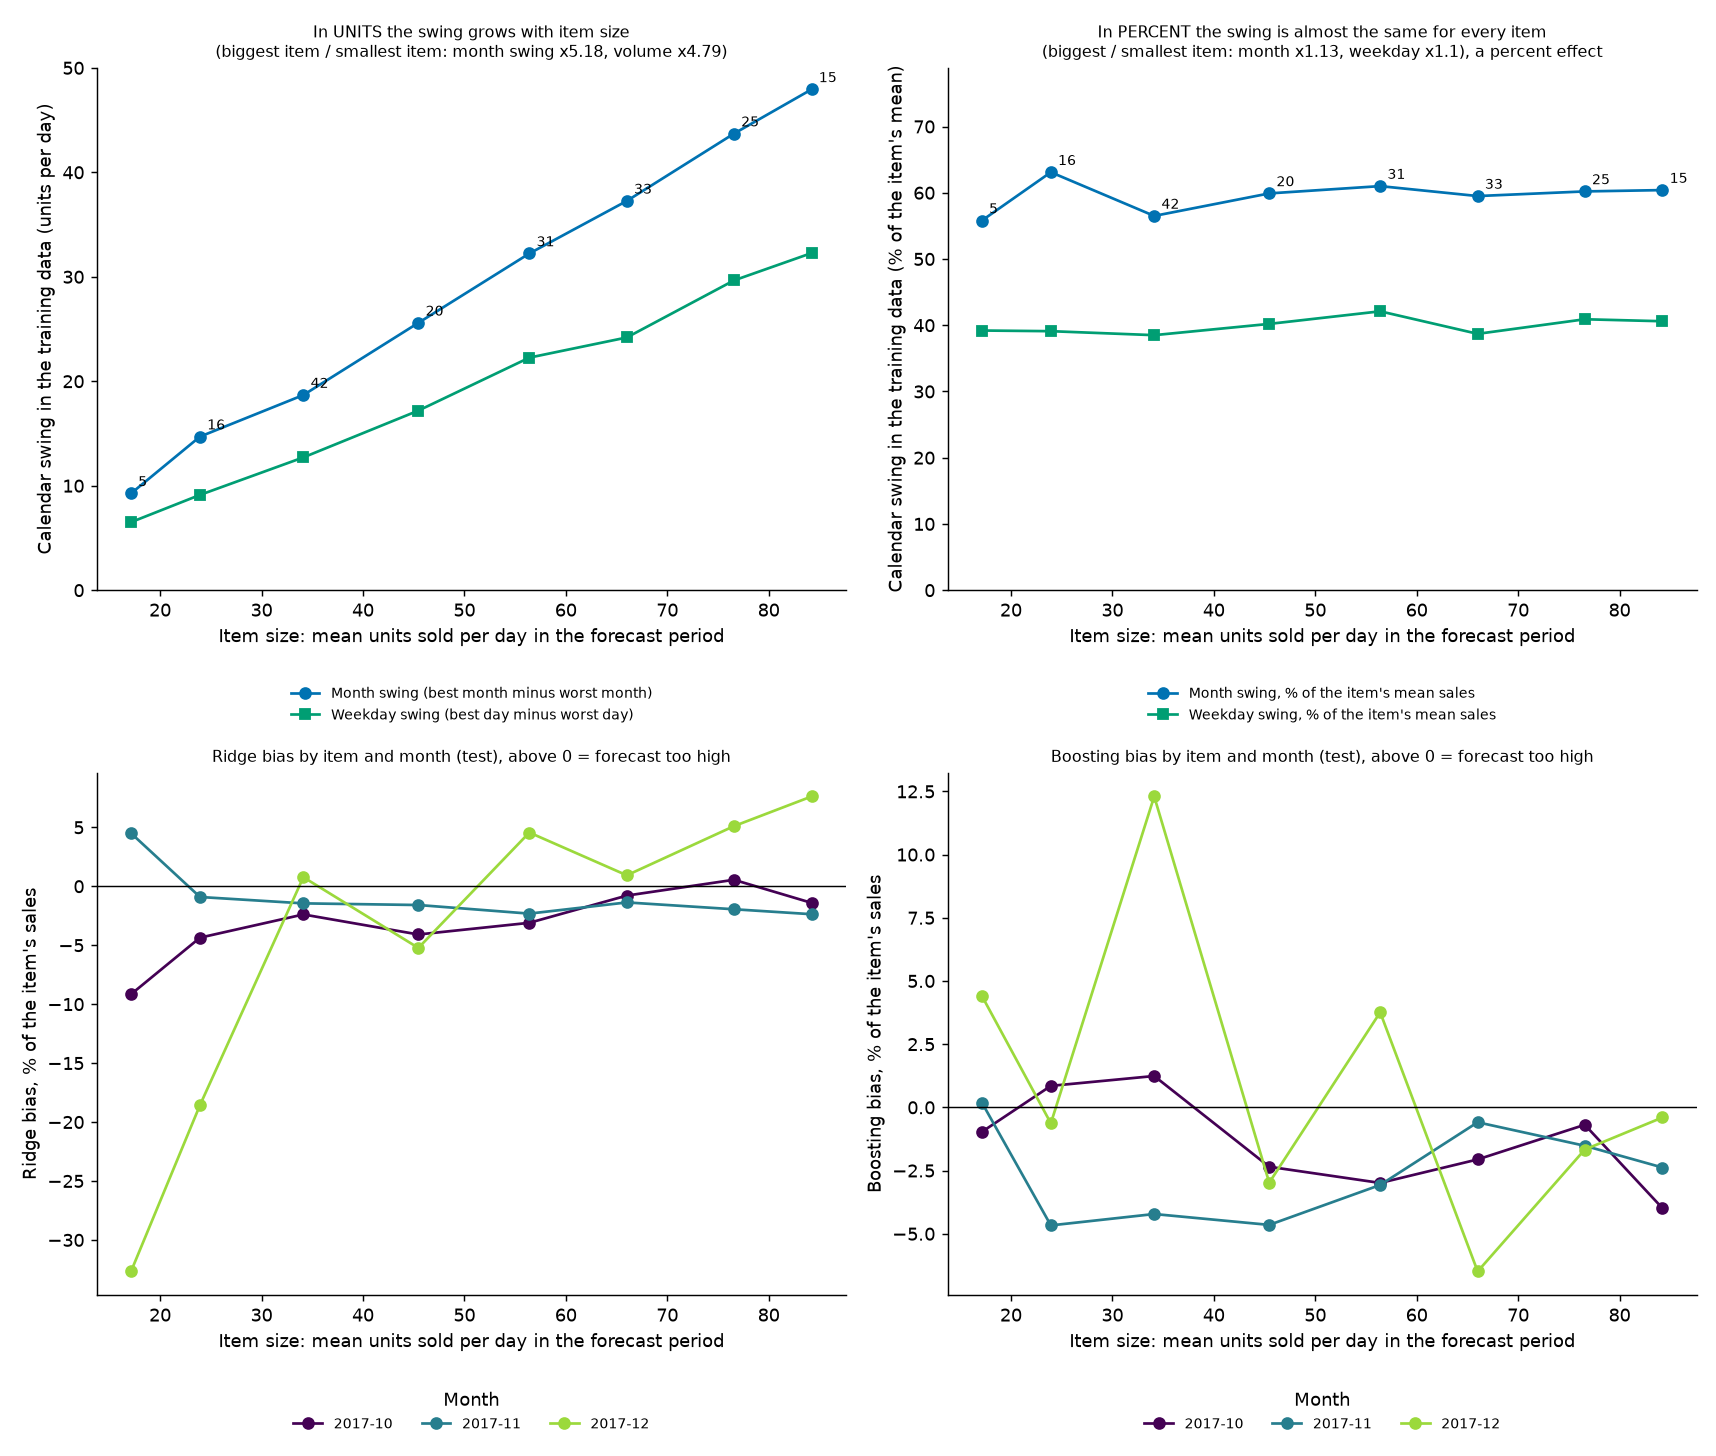

Do forecasts stop short of record sales? (a 'ceiling' check)


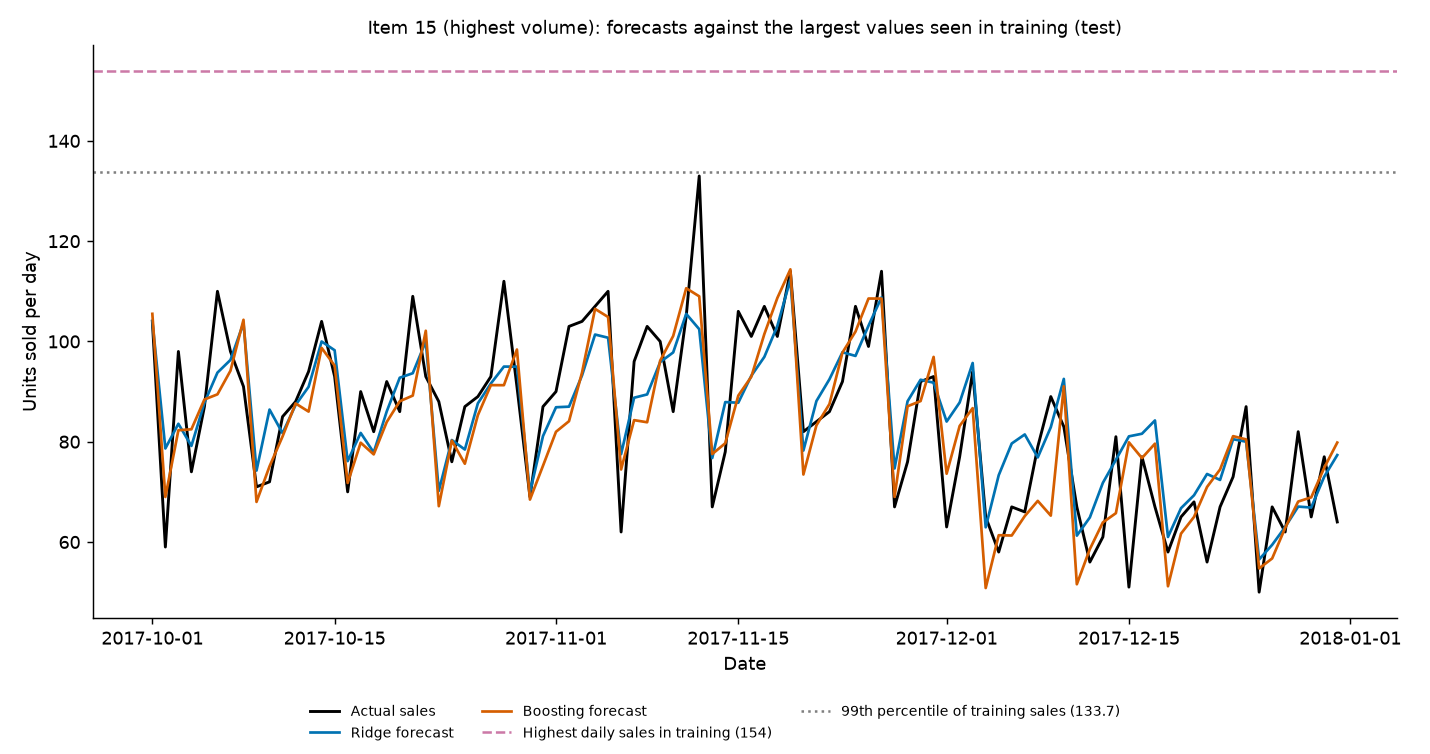

In [47]:
show_fig("failure_test_rule_beats_hgb.png", "An item where the best simple rule beats boosting (weekly totals)")
show_fig("failure_test_by_item.png", "Error by item")
show_fig("failure_test_noise.png", "Errors compared with pure counting noise")
show_fig("failure_test_bias.png", "Bias by month and weekday, and how it scales with item volume")
show_fig("failure_test_ceiling.png", "Do forecasts stop short of record sales? (a 'ceiling' check)")

### Where does a simple rule win on the test?
For each model and measure, the number of the 8 items on which the best simple rule did better than the model.

In [48]:
rows = []
for m in (HEAD, OTHER):
    for measure in ("daily_mae", "weekly_mae", "order_cost"):
        s = fs["simple_rule_wins"][m][measure]
        rows.append({"model": NAMES[m], "measure": measure.replace("_", " "), "items where a simple rule wins": f"{s['n_items_baseline_wins']} of {s['n_items']}",
                     "which": ", ".join(f"{c['item']} ({SHORT[c['best_baseline']]})" for c in s["cases"])})
display(pd.DataFrame(rows))

,model,measure,items where a simple rule wins,which
0,Gradient boosting,daily mae,0 of 8,
1,Gradient boosting,weekly mae,0 of 8,
2,Gradient boosting,order cost,1 of 8,25 (lag 364)
3,Ridge regression,daily mae,1 of 8,5 (mean4)
4,Ridge regression,weekly mae,4 of 8,"5 (lag 364), 16 (lag 7), 25 (lag 364), 15 (lag 7)"
5,Ridge regression,order cost,5 of 8,"5 (mean4), 16 (lag 7), 20 (lag 7), 25 (lag 364..."


### Compared with what validation showed
The same analysis on the validation quarter (read from `results/failure_validation_summary.json`, produced before the test) next to the test.

In [49]:
with open(RESULTS / "failure_validation_summary.json") as f:
    fv = json.load(f)
rows = []
for m in (HEAD, OTHER):
    for label, src in (("validation", fv), ("test", fs)):
        nc, o = src["noise_check"][m], src["overall"][m]
        rows.append({"model": NAMES[m], "period": label, "daily MAE": o["mae"], "noise floor": o["noise_floor_mae"],
                     "bias": o["bias"], "biggest miss": nc["max_abs_error"], "biggest miss, noise only (mean)": nc["noise_only_max_abs_error_mean"],
                     "days over 3 noise units": nc["days_noise_units_over_3"], "expected from noise": nc["days_noise_units_over_3_expected_pure_noise"],
                     "simple rule wins on order cost": f"{src['simple_rule_wins'][m]['order_cost']['n_items_baseline_wins']} of 8"})
display(pd.DataFrame(rows))

,model,period,daily MAE,noise floor,bias,biggest miss,"biggest miss, noise only (mean)",days over 3 noise units,expected from noise,simple rule wins on order cost
0,Gradient boosting,validation,6.6300,6.0830,-0.3936,30.94,30.67,10,2.12,5 of 8
1,Gradient boosting,test,6.1778,5.4392,-0.8273,28.88,27.73,6,2.16,1 of 8
2,Ridge regression,validation,6.5156,6.0854,-0.2781,31.59,30.49,8,2.14,6 of 8
3,Ridge regression,test,6.3831,5.4155,-0.6226,30.55,27.74,18,2.18,5 of 8


### What the failure analysis says (evidence first, hypotheses labelled)
*(From `results/failure_test_summary.json` and the `failure_test_*.csv` files. A "hypothesis" is an idea the numbers fit but do not prove.)*

**Main finding.** Much of the remaining error looks like random noise, and no single failure dominates. Boosting's average daily miss is 6.18 units against a noise floor of 5.44, and its biggest single miss (28.9 units) is inside the range that pure noise would give. A little more than noise remains (6 days are more than 3 noise units off, where 2.2 would be expected), but I cannot say how much.

**The worst days look like surprises in the sales.** The worst day is item 15 on 2017-12-15: forecast 79.9, actual 51. The simple rules forecast 79, 89 and 83, so they missed too. Of the 10 worst days, 9 were missed in the same direction by all three simple rules.

**One wrong example.** Item 25, week of 2017-12-11 (chosen by a fixed rule, shown in the figure above): boosting forecast 411.4, actual 475.0 (-13.4%). The simple rules forecast 448, 532 and 428, and Ridge, at 467.6, was close. **Hypothesis, not tested:** boosting followed the fall in the weeks before, and the rise was not predictable from past sales.

**Boosting leans low.** Its average bias is -0.83 units per day, and it is negative on 6 of 8 items.

**What I cannot say.** Eight items and 13 weeks cannot show why a model is wrong in general. I do not know the reasons for the surprise days, and the data looks synthetic.

## 12. Limitations

Please read the test numbers with these in mind:
- **Small sample.** 13 test weeks (104 item-weeks) from one store and one quarter. Another quarter or store could rank the methods differently.
- **Simple orders.** Weekly totals ignore stock-outs inside the week, so real lost sales would be higher. Leftover stock is not carried over.
- **Assumed costs.** 3 : 1 is my guess; 1 : 1 and 5 : 1 are checks. A real owner would use real margins and storage costs.
- **Sunday's sales are assumed to be known on Monday morning.** If the owner must order earlier, every lag would need to be at least 8 days, and the forecasts would be a little worse.
- **The data looks synthetic.** The patterns are very regular and the leftover noise behaves like counting noise, so real errors are probably larger. The shop owner is an illustration only.
- **Tuned on validation.** I chose the buffers and the main model on validation weeks, so validation costs are optimistic. The buffers came from models trained before the validation period and were reused for the final models, which may bias the result in an unknown direction. The test numbers are the ones to use.
- **Choices made after looking at validation** are listed in section 7, including the switch of the main model from Ridge to boosting.
- **Test period.** I fixed every choice before using the test period for evaluation, except that an early figure showed Oct to Dec 2017 sales once, before modelling; nothing was tuned on it. The guard stops accidents, not cheating: the loader reads the whole `train.csv` before dropping the later rows, so someone determined could read the file directly.
- **Failure analysis.** It covers 8 items and one quarter. Reasons are hypotheses unless the numbers directly support them.
- **Run log.** After the results were final, the comments were shortened and tidied, four messages were reworded and `scipy` was pinned in `requirements.txt`; no logic changed, the run log was restarted, and the results are identical to before. The log shows the first run and later re-runs, each verified as identical.

## 13. Sources

In [50]:
from importlib.metadata import version
libs = ["pandas", "numpy", "scikit-learn", "matplotlib", "scipy", "nbformat", "nbconvert", "ipykernel", "jupyter", "lightgbm"]
rows = []
for name in libs:
    try:
        rows.append({"library": name, "installed version": version(name)})
    except Exception:
        rows.append({"library": name, "installed version": "not installed"})
display(pd.DataFrame(rows).set_index("library"))
print("Pinned in requirements.txt:")
print((ROOT / "requirements.txt").read_text())

,installed version
library,
pandas,3.1.1
numpy,2.5.4
scikit-learn,1.9.1
matplotlib,3.11.2
scipy,1.18.1
nbformat,5.11.1
nbconvert,7.17.2
ipykernel,7.4.0
jupyter,1.1.1


Pinned in requirements.txt:
pandas==3.1.1
numpy==2.5.4
scikit-learn==1.9.1
matplotlib==3.11.2
jupyter==1.1.1
nbconvert==7.17.2
ipykernel==7.4.0
lightgbm==4.7.0
scipy==1.18.1



- **Data:** Kaggle competition "Store Item Demand Forecasting Challenge" (https://www.kaggle.com/c/demand-forecasting-kernels-only). The file `train.csv` is included here for convenience; see `data/README.md`. Anonymised data, 10 stores x 50 items, daily sales 2013 to 2017. Kaggle's terms apply.
- **Libraries:** pandas, numpy, scikit-learn (Ridge and HistGradientBoostingRegressor), matplotlib, scipy (the shuffle tests in the failure analysis), Jupyter with nbconvert and ipykernel to run the notebook. Versions are in `requirements.txt` (scipy is pinned there too). `lightgbm` is installed from `requirements.txt` but not used.
- **AI tools:** I used AI tools (Claude by Anthropic, through Claude Code) a lot in this project. The AI suggested the architecture and the algorithms, wrote much of the code with me, wrote the GUI launcher and helped write this README. I picked the idea, made the final decisions (for example which model is the main one) and checked the results. Each part was also checked in a separate AI review pass.
- **Tutorials:** No code was copied from tutorials or other notebooks. I looked at other people's code for ideas.
- **Licence:** The code is under the MIT licence (see `LICENSE`).